# DMS v6 — Hành vi / Mắt nhắm–mở / Ngáp

Ba model độc lập, 18 cell code, code hiển thị trực tiếp trong notebook.

| Model | Dữ liệu | Nhãn | ROI |
|---|---|---|---|
| behavior | State Farm + 3MDAD RGB1 | distracted / drowsy / normal / phone | Toàn ảnh |
| eyes | Yawn Eye: Closed, Open | closed / open | Một mắt |
| yawn | Yawn Eye: no_yawn, yawn | not_yawn / yawn | Mặt YuNet |

**Chạy:** upload lên Colab, bật T4 GPU, chỉnh Cell 2 rồi Run all. Tự tải ba nguồn (3MDAD chỉ lấy mẫu RGB1 bằng HTTP Range),
không cần upload CSV. DDD không được dùng để thay thế nhãn mắt trong bản này.
`quick_check` chạy thử CPU tối đa 2 epochs; train thật cần GPU.

Ảnh mắt có sẵn đã là crop một mắt: không chạy face detector trên ảnh này.
Camera dùng landmark YuNet để cắt từng mắt, chạy cùng model rồi lấy trung bình
xác suất khi tìm được đủ hai mắt. Thiếu mặt/mắt trả unknown.
Nhánh hành vi thêm **drowsy = fatigue and somnolence (3MDAD AC12)**, có thể gồm gật gù, ngáp, dụi mắt. Đây là nhãn của chuỗi hành động, không phải xác nhận ngủ/gục đầu ở từng frame. Demo có thêm cảnh báo nhắm mắt kéo dài độc lập.
Ngưỡng thời gian là cấu hình demo, cần hiệu chỉnh trên video có nhãn.

State Farm tách theo tài xế. Mắt/ngáp chia theo cụm ảnh gốc/ROI trước train;
chưa có ID đáng tin cậy nên không tuyên bố độc lập theo người. Phép chia nội bộ
không phải benchmark gốc. Cần đánh giá thêm với người và camera mới.
Không dùng điểm test để chọn checkpoint/cấu hình triển khai.

3MDAD có ID người thật, tách theo người trong từng nguồn; mỗi split có đủ bốn lớp từ 3MDAD. Chỉ dùng cho nghiên cứu phi thương mại theo nguồn tác giả. Nhánh drowsy chỉ có một nguồn dương tính nên vẫn cần kiểm tra trên camera/người mới.


## Bản cải tiến train nhanh và giảm overfit

Giữ cách chia theo người/cụm và khóa lựa chọn bằng validation. Nhánh hành vi dùng
cân bằng lớp một phần (alpha=0.5), cân bằng tài xế/nguồn trong lớp, dropout 0.30,
weight decay 0.001, learning rate thấp hơn và đóng băng bốn block đầu.
Cache ảnh resized ở RAM uint8 dùng chung; augmentation theo batch trên GPU;
chọn batch bằng đo tốc độ thực trong ngân sách VRAM và giới hạn số bước/epoch.
Không cần cố lấp đầy VRAM khi batch lớn hơn không tăng tốc.
Kết quả cũ được giữ ở model_dms_v6_trained_reference.ipynb. Bản này cần train lại;
thử 2 epoch chỉ kiểm tra pipeline, không chứng minh độ chính xác hoặc hết overfit.


## Cell 1. Cài thư viện

**Làm gì:** Cài các package cần cho xử lý ảnh, train và xuất ONNX.

**Đầu ra:** Môi trường có đủ thư viện.

In [1]:
# CELL 1: CÀI THƯ VIỆN
# Mục đích: Cài các package cần cho xử lý ảnh, train và xuất ONNX.
# Kết quả: Môi trường có đủ thư viện.


# 1. Cài các thư viện công khai (không cài helper riêng)
%pip install -q "ultralytics==8.4.49" "onnx>=1.16,<2" "onnxruntime>=1.18,<2" kagglehub pandas scipy scikit-learn matplotlib requests tqdm psutil

## Cell 2. Cấu hình thí nghiệm

**Làm gì:** Import thư viện, đặt nhãn, đường dẫn, seed và các cấu hình cần train.

**Đầu ra:** WORK, TASKS, EXPERIMENTS và config.json.

**Cell cần chỉnh:** `PROFILE`, `EPOCHS`, `SAVE_TO_DRIVE`. `balanced` mặc định; `quick_check` chỉ chạy thử tối đa 2 epochs. Bật lưu Drive trước khi Run all nếu muốn sao lưu.

In [2]:
# CELL 2: CẤU HÌNH THÍ NGHIỆM
# Mục đích: Import thư viện, đặt nhãn, đường dẫn, seed và các cấu hình cần train.
# Kết quả: WORK, TASKS, EXPERIMENTS và config.json.


import os
import sys
import subprocess
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
BASE = Path('/content') if IN_COLAB else Path.cwd()
RUNTIME = BASE / 'dms_v6_pi_files'
RUNTIME.mkdir(parents=True, exist_ok=True)
(RUNTIME / '.yolo_config').mkdir(parents=True, exist_ok=True)
os.environ['YOLO_CONFIG_DIR'] = str(RUNTIME / '.yolo_config')
import hashlib
import inspect
import json
import os
import random
import shutil
import time
from copy import copy
import gc
import psutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torchvision.transforms as T
from PIL import Image, ImageOps
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from tqdm.auto import tqdm
from ultralytics import YOLO
from ultralytics.data.dataset import ClassificationDataset
from ultralytics.models.yolo.classify import ClassificationTrainer, ClassificationValidator
import re
import warnings
import cv2
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, WeightedRandomSampler
import io
import zipfile
import requests
import gzip
from pathlib import Path, PurePosixPath
import stat
import tarfile
from urllib.parse import urlparse

try:
    from IPython.display import display
except ImportError:
    display = print
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cpu':
    print('Chưa có GPU: vẫn chuẩn bị dữ liệu được. Train đầy đủ cần bật T4 trước cell train.')
else:
    print('GPU:', torch.cuda.get_device_name(0))

# --- Nhãn và nguồn dữ liệu ---
TASKS = {
    'behavior': ['distracted', 'drowsy', 'normal', 'phone'],
    'eyes': ['closed', 'open'],
    'yawn': ['not_yawn', 'yawn'],
}
CLASSES = list(TASKS['behavior'])
SF_MAP = {f'c{i}': ('normal' if i == 0 else 'phone' if i < 5 else 'distracted') for i in range(10)}
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
ARCHIVE_EXTENSIONS = {'.tar', '.tgz', '.gz', '.zip', '.rar', '.7z'}
BASE_SIZE = 320
ACTIVE_TASK = None
ACTIVE_FRAMES = None
ACTIVE_SEGMENTS = None
DATASETS = {
    'state_farm': ('rightway11/state-farm-distracted-driver-detection', 1),
    'yawn_eye': ('serenaraju/yawn-eye-dataset-new', 1),
    'three_mdad': ('anouarbenkhalifa/3mdad-multimodal-driver-action-distraction', 1),
}
MODEL_NAME = 'face_detection_yunet_2023mar.onnx'
MODEL_SHA256 = '8f2383e4dd3cfbb4553ea8718107fc0423210dc964f9f4280604804ed2552fa4'

# Lưu cấu hình hoặc kết quả thành JSON để xem lại sau khi train.
def write_json(path, value):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')

# Cố định seed cho Python, NumPy và PyTorch.
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Tính checksum để kiểm tra đúng file model.
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

# Đưa ảnh về khung vuông, giữ tỉ lệ và thêm padding.
def square_image(image, size=BASE_SIZE):
    """Identical first step for materialized training images and Pi inference."""
    image = ImageOps.exif_transpose(image).convert('RGB')
    return ImageOps.pad(image, (size, size), method=Image.Resampling.BILINEAR, color=(114, 114, 114), centering=(0.5, 0.5))

# Liệt kê các file ảnh trong thư mục dữ liệu.
def image_files(root):
    return sorted((p.resolve() for p in Path(root).rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS))

# Đặt nhãn và dữ liệu đang dùng cho một trong ba nhánh.
def activate(task, frames=None, segments=None):
    global CLASSES
    'Training is sequential on one GPU; task-specific labels are explicit.'
    global ACTIVE_TASK, ACTIVE_FRAMES, ACTIVE_SEGMENTS
    CLASSES = list(TASKS[task])
    ACTIVE_TASK, ACTIVE_FRAMES, ACTIVE_SEGMENTS = (task, frames, segments)

# --- CẤU HÌNH CẦN CHỈNH KHI CHẠY ---
PROFILE = "balanced" # @param ["quick_check", "balanced", "thorough"]
EPOCHS = 30 # @param {type:"integer"}
SEED = 42
CPU_COUNT = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else (os.cpu_count() or 2)
NUM_WORKERS = min(8, max(2, CPU_COUNT // 2)) if IN_COLAB else 0
PREFETCH_FACTOR = 2
CACHE_IMAGES_RAM = True
CACHE_MAX_GB = 8.0
CACHE_RAM_FRACTION = .35
GPU_MEMORY_TARGET = .75
MAX_GPU_BATCH = 512
MIN_STEPS_PER_EPOCH = 40
BEHAVIOR_BALANCE_ALPHA = .5  # 0=natural class mass, 1=equal class mass
FAST_CUDNN = True  # faster fixed image shapes; repeated runs may differ slightly
torch.backends.cudnn.benchmark = bool(FAST_CUDNN and torch.cuda.is_available())
cv2.setNumThreads(0)
SAVE_TO_DRIVE = False # @param {type:"boolean"}
DRIVE_RESULTS_FOLDER = '/content/drive/MyDrive/dms_results'
STATE_FARM_EXISTING_FOLDER = ''
YAWN_EXISTING_FOLDER = ''
MDAD_EXISTING_FOLDER = '' # folder RGB1 đã giải nén, nếu có
MDAD_FRAMES_PER_ACTION = 24 # mẫu đều/người/hành vi, không sao chép tất cả frame gần nhau
if not 2 <= MDAD_FRAMES_PER_ACTION <= 150:
    raise ValueError('MDAD_FRAMES_PER_ACTION phải nằm trong [2, 150].')
if EPOCHS < 1 or NUM_WORKERS < 0:
    raise ValueError('EPOCHS >= 1 và NUM_WORKERS >= 0.')
if PROFILE not in {'quick_check', 'balanced', 'thorough'}:
    raise ValueError('PROFILE không hợp lệ.')
if SAVE_TO_DRIVE:
    if not IN_COLAB:
        raise RuntimeError('Drive mount chỉ dùng trên Google Colab.')
    from google.colab import drive
    drive.mount('/content/drive')
from datetime import datetime
from zoneinfo import ZoneInfo
RUN_NAME = 'dms_v6_' + datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).strftime('%Y%m%d_%H%M%S_%f')
WORK = BASE / RUN_NAME
WORK.mkdir(parents=True, exist_ok=False)
CACHE = BASE / '.cache' / 'dms_v6_data'
BACKUP = Path(DRIVE_RESULTS_FOLDER) / RUN_NAME if SAVE_TO_DRIVE else None
seed_everything(SEED)

def backup_results():
    if BACKUP is None:
        return
    for path in WORK.rglob('*'):
        if not path.is_file():
            continue
        relative = path.relative_to(WORK)
        if any((s in {'dataset', 'face_frames', '__pycache__', 'runtime'} for s in relative.parts)):
            continue
        if path.suffix.lower() not in {'.pt', '.onnx', '.json', '.csv', '.yaml', '.txt', '.zip'}:
            continue
        if 'runs' in relative.parts and path.suffix not in {'.csv', '.yaml'}:
            continue
        destination = BACKUP / relative
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, destination)
    print('Đã sao lưu kết quả:', BACKUP)
EXPERIMENTS = {
    'behavior': [dict(name='nano224', model='yolo11n-cls.pt', imgsz=224, batch='auto', lr0=.0001, dropout=.30, weight_decay=.001, freeze=4),
                 dict(name='small224', model='yolo11s-cls.pt', imgsz=224, batch='auto', lr0=.00005, dropout=.30, weight_decay=.001, freeze=4)],
    'eyes': [dict(name='nano128', model='yolo11n-cls.pt', imgsz=128, batch='auto', lr0=.00015)],
    'yawn': [dict(name='nano160', model='yolo11n-cls.pt', imgsz=160, batch='auto')],
}
if PROFILE == 'thorough':
    EXPERIMENTS['eyes'].append(dict(name='nano160', model='yolo11n-cls.pt', imgsz=160, batch='auto', lr0=.00015))
    EXPERIMENTS['yawn'].append(dict(name='nano224', model='yolo11n-cls.pt', imgsz=224, batch='auto'))
if PROFILE == 'quick_check':
    EPOCHS = min(EPOCHS, 2)
    EXPERIMENTS = {task: candidates[:1] for task, candidates in EXPERIMENTS.items()}
write_json(WORK / 'config.json', dict(profile=PROFILE, seed=SEED, epochs=EPOCHS, experiments=EXPERIMENTS, datasets=DATASETS, performance=dict(workers=NUM_WORKERS, ram_cache=CACHE_IMAGES_RAM, ram_cache_max_gb=CACHE_MAX_GB, gpu_memory_target=GPU_MEMORY_TARGET, max_gpu_batch=MAX_GPU_BATCH, min_steps_per_epoch=MIN_STEPS_PER_EPOCH, behavior_balance_alpha=BEHAVIOR_BALANCE_ALPHA, cudnn_benchmark=FAST_CUDNN), selection='Validation image macro-F1, including missing face ROI as unknown for face tasks.'))
freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True).stdout
(WORK / 'requirements_resolved.txt').write_text(freeze, encoding='utf-8')
print('Profile:', PROFILE, '| số ứng viên:', sum(map(len, EXPERIMENTS.values())))
print('Kết quả:', WORK, '| backup:', BACKUP)
print('Runtime trống: %.1f GB' % (shutil.disk_usage(BASE).free / 1024 ** 3))

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/content/dms_v6_pi_files/.yolo_config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU: Tesla T4
Profile: balanced | số ứng viên: 4
Kết quả: /content/dms_v6_20261120_194102_102132 | backup: None
Runtime trống: 235.4 GB


## Cell 3. Chuẩn bị cách tải dữ liệu

**Làm gì:** Khai báo các hàm tải tiếp, giải nén và tự lấy metadata State Farm.

**Đầu ra:** Các hàm tải dữ liệu; cell này chưa tải bộ ảnh.

In [3]:
# CELL 3: CHUẨN BỊ CÁCH TẢI DỮ LIỆU
# Mục đích: Khai báo các hàm tải tiếp, giải nén và tự lấy metadata State Farm.
# Kết quả: Các hàm tải dữ liệu; cell này chưa tải bộ ảnh.


# Kiểm tra file giải nén luôn nằm trong thư mục đích.
def safe_target(root, member):
    normalized = str(member).replace('\\', '/')
    path = PurePosixPath(normalized)
    if path.is_absolute() or '..' in path.parts or any((':' in p for p in path.parts)):
        raise ValueError(f'Unsafe archive path: {member}')
    root = Path(root).resolve()
    target = (root / Path(*path.parts)).resolve()
    if not target.is_relative_to(root):
        raise ValueError(f'Archive path escapes destination: {member}')
    return target

# Ghi một file trong archive; bỏ qua file đã giải nén hoàn chỉnh.
def _copy_member(stream, target, expected_size=None):
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.is_file() and expected_size is not None and (target.stat().st_size == expected_size):
        return
    part = target.with_name(target.name + '.extracting')
    with open(part, 'wb') as out:
        shutil.copyfileobj(stream, out, length=1024 * 1024)
    if expected_size is not None and part.stat().st_size != expected_size:
        raise IOError(f'Incomplete extraction: {target.name}')
    os.replace(part, target)

# Giải nén dữ liệu, kiểm tra đường dẫn và file lồng nhau.
def extract_archive(archive, destination, scratch, max_depth=3):
    """Unpack tar→rar (YawDD), zip, tar.gz, or ordinary rar/7z without executing files."""
    archive, destination, scratch = (Path(archive), Path(destination), Path(scratch))
    destination.mkdir(parents=True, exist_ok=True)
    scratch.mkdir(parents=True, exist_ok=True)
    nested = []

    def output_path(name):
        if Path(str(name).replace('\\', '/')).suffix.lower() in ARCHIVE_EXTENSIONS:
            target = safe_target(scratch / 'nested', name)
            nested.append(target)
            return target
        return safe_target(destination, name)
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as z:
            for entry in z.infolist():
                safe_target(destination, entry.filename)
                if stat.S_ISLNK(entry.external_attr >> 16):
                    raise ValueError('Archive symbolic links are not accepted.')
                if entry.is_dir():
                    continue
                with z.open(entry) as stream:
                    _copy_member(stream, output_path(entry.filename), entry.file_size)
    elif tarfile.is_tarfile(archive):
        with tarfile.open(archive, 'r:*') as tf:
            for entry in tf:
                safe_target(destination, entry.name)
                if entry.isdir():
                    continue
                if not entry.isfile():
                    raise ValueError('Archive links/special files are not accepted.')
                with tf.extractfile(entry) as stream:
                    _copy_member(stream, output_path(entry.name), entry.size)
    else:
        with archive.open('rb') as f:
            magic = f.read(8)
        if magic[:2] == b'\x1f\x8b':
            inner = scratch / 'gzip_payload'
            with gzip.open(archive, 'rb') as stream:
                _copy_member(stream, inner)
            nested.append(inner)
        else:
            try:
                import libarchive
            except (ImportError, OSError) as e:
                raise RuntimeError('RAR extraction needs pip install libarchive-c and system libarchive.') from e
            with libarchive.file_reader(str(archive)) as entries:
                for entry in entries:
                    safe_target(destination, entry.pathname)
                    if entry.isdir:
                        continue
                    if entry.issym or entry.islnk or (not entry.isfile):
                        raise ValueError('Archive links/special files are not accepted.')
                    target = output_path(entry.pathname)
                    target.parent.mkdir(parents=True, exist_ok=True)
                    expected = entry.size
                    if target.is_file() and expected is not None and (target.stat().st_size == expected):
                        continue
                    part = target.with_name(target.name + '.extracting')
                    with part.open('wb') as out:
                        for block in entry.get_blocks():
                            out.write(block)
                    if expected is not None and part.stat().st_size != expected:
                        raise IOError(f'Incomplete RAR entry: {target.name}')
                    os.replace(part, target)
    if nested and max_depth <= 0:
        raise ValueError('Archive nesting is deeper than expected.')
    for child in nested:
        extract_archive(child, destination, scratch / ('level_' + str(max_depth)), max_depth - 1)

# Tải archive qua HTTP, hỗ trợ tải tiếp và kiểm tra kích thước.
def download_archive(url, cache, source, expected_bytes=None):
    """Stream and resume supported HTTP downloads; never store signed URLs in receipts."""
    parsed = urlparse(url)
    if parsed.scheme not in {'http', 'https'} or not parsed.netloc:
        raise ValueError('Provide an HTTP(S) archive download URL.')
    cache = Path(cache)
    cache.mkdir(parents=True, exist_ok=True)
    digest = hashlib.sha256(url.encode()).hexdigest()
    target = cache / f'{source}_{digest[:16]}.archive'
    receipt = target.with_suffix('.download.json')
    if target.is_file() and receipt.is_file():
        info = json.loads(receipt.read_text(encoding='utf-8'))
        if info['bytes'] == target.stat().st_size and info['url_sha256'] == digest:
            if expected_bytes is None or info['bytes'] == expected_bytes:
                return target
    part = target.with_suffix('.part')
    if parsed.netloc.lower() in {'drive.google.com', 'docs.google.com'}:
        if '/folders/' in parsed.path:
            raise ValueError('Use a direct archive file link, not a Google Drive folder link.')
        import gdown
        result = gdown.download(url=url, output=str(part), fuzzy=True, resume=True, quiet=False)
        if result is None:
            raise RuntimeError('Drive archive could not be downloaded; check access or quota.')
        total = part.stat().st_size
    else:
        offset = part.stat().st_size if part.is_file() else 0
        headers = {'User-Agent': 'DMS-Colab-Downloader/1.0'}
        if offset:
            headers['Range'] = f'bytes={offset}-'
        with requests.get(url, headers=headers, stream=True, timeout=(20, 90)) as response:
            if response.status_code not in {200, 206}:
                raise RuntimeError(f'Download failed: HTTP {response.status_code} from {parsed.netloc}')
            if 'text/html' in response.headers.get('Content-Type', '').lower():
                raise ValueError('Received an HTML/login page; provide the actual archive download URL.')
            if response.status_code == 206:
                content_range = response.headers.get('Content-Range', '')
                if not content_range.startswith(f'bytes {offset}-'):
                    raise ValueError('Server returned an unexpected resume range.')
            else:
                offset = 0
            length = int(response.headers.get('Content-Length', 0))
            total = offset + length if length else None
            if expected_bytes is not None and total is not None and (total != expected_bytes):
                raise ValueError('Download size differs from the verified source size.')
            needed = max(0, (total or expected_bytes or 0) - offset)
            if needed and shutil.disk_usage(cache).free < needed + 512 * 1024 ** 2:
                raise OSError('Not enough free runtime disk space for this archive.')
            with part.open('ab' if offset else 'wb') as out, tqdm(total=total, initial=offset, unit='B', unit_scale=True, desc=source) as bar:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk:
                        out.write(chunk)
                        bar.update(len(chunk))
        if total is not None and part.stat().st_size != total:
            raise IOError('Download incomplete; rerun this cell to resume.')
        total = part.stat().st_size
    if expected_bytes is not None and total != expected_bytes:
        raise IOError('Download does not match the expected file size.')
    os.replace(part, target)
    receipt.write_text(json.dumps(dict(url_sha256=digest, host=parsed.netloc, bytes=total)), encoding='utf-8')
    return target

# Tự lấy bảng tài xế State Farm nếu bộ ảnh chưa có CSV.
def ensure_state_farm_metadata(root, session=requests):
    root = Path(root)
    existing = sorted(root.rglob('driver_imgs_list.csv'))
    if existing:
        return existing[0]
    url = 'https://www.kaggle.com/api/v1/datasets/download/rightway11/state-farm-distracted-driver-detection/driver_imgs_list.csv'
    response = session.get(url, timeout=(20, 60))
    response.raise_for_status()
    payload = response.content
    if payload.startswith(b'PK'):
        with zipfile.ZipFile(io.BytesIO(payload)) as z:
            names = [n for n in z.namelist() if Path(n).name == 'driver_imgs_list.csv']
            if len(names) != 1:
                raise ValueError('Metadata archive has no unique driver_imgs_list.csv.')
            payload = z.read(names[0])
    meta = pd.read_csv(io.BytesIO(payload), dtype=str)
    if not {'subject', 'classname', 'img'}.issubset(meta) or meta.empty:
        raise ValueError('Public State Farm metadata is invalid. Rerun the data-download cell.')
    if meta[['subject', 'classname', 'img']].isna().any().any() or meta.duplicated(['classname', 'img']).any():
        raise ValueError('State Farm metadata has empty or ambiguous identities.')
    root.mkdir(parents=True, exist_ok=True)
    target = root / 'driver_imgs_list.csv'
    target.write_bytes(payload)
    return target

# Lấy ba nguồn dữ liệu từ cache, folder có sẵn hoặc Kaggle.

# Chỉ lấy RGB1 ban ngày và mẫu đều theo người/hành vi từ ZIP Kaggle chính thức.
# Không tải depth/IR/RGB2, không tải toàn bộ archive 38 GB về Colab.
class RangeArchive(io.RawIOBase):
    def __init__(self, url, session=None, block_size=4 * 1024 ** 2):
        self.session = session or requests.Session()
        with self.session.get(url, headers={'Range': 'bytes=0-0', 'Accept-Encoding': 'identity'},
                              stream=True, timeout=(20, 90)) as response:
            response.raise_for_status()
            content_range = response.headers.get('Content-Range', '')
            if response.status_code != 206 or not content_range.startswith('bytes 0-0/'):
                raise RuntimeError('3MDAD: server không hỗ trợ Range. Dùng MDAD_EXISTING_FOLDER; không tự tải toàn bộ 38 GB.')
            self.size = int(content_range.split('/')[-1])
            self.url = response.url
        self.pos, self.block_size, self.block_start, self.block = 0, block_size, -1, b''
        self.transferred = 0

    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.pos

    def seek(self, offset, whence=0):
        self.pos = offset if whence == 0 else self.pos + offset if whence == 1 else self.size + offset
        if self.pos < 0:
            raise ValueError('Negative archive position')
        return self.pos

    def fetch(self, start, count):
        end = min(self.size, start + count) - 1
        if end < start: return b''
        for attempt in range(3):
            try:
                with self.session.get(self.url, headers={'Range': f'bytes={start}-{end}', 'Accept-Encoding': 'identity'},
                                      stream=True, timeout=(20, 120)) as response:
                    response.raise_for_status()
                    expected = f'bytes {start}-{end}/{self.size}'
                    if response.status_code != 206 or response.headers.get('Content-Range') != expected:
                        raise ValueError('3MDAD: Range/cache response mismatch; refused full download.')
                    chunks, received = [], 0
                    for chunk in response.iter_content(1024 ** 2):
                        if not chunk: continue
                        chunks.append(chunk)
                        received += len(chunk)
                        if received > end - start + 1:
                            raise ValueError('3MDAD: range response exceeded the requested size.')
                        if count > self.block_size and received % (8 * 1024 ** 2) == 0:
                            print(f'3MDAD ZIP directory: {received / 1024**2:.0f}/{count / 1024**2:.0f} MiB', flush=True)
                    payload = b''.join(chunks)
                if len(payload) != end - start + 1:
                    raise IOError('3MDAD: incomplete range; rerun cell to resume cached images.')
                self.transferred += len(payload)
                return payload
            except (requests.RequestException, IOError):
                if attempt == 2:
                    raise RuntimeError('3MDAD: lỗi kết nối khi đọc archive. Chạy lại cell để dùng cache hoặc đặt MDAD_EXISTING_FOLDER.') from None
        raise IOError('Range read failed')

    def read(self, count=-1):
        if count < 0: count = self.size - self.pos
        count = min(count, max(0, self.size - self.pos))
        if count == 0: return b''
        if count > 128 * 1024 ** 2:
            raise ValueError('3MDAD: ZIP metadata unexpectedly large; use extracted RGB1 folder.')
        if count > self.block_size:
            print(f'3MDAD: reading ZIP directory ({count / 1024**2:.1f} MiB)', flush=True)
            data = self.fetch(self.pos, count)
            self.pos += len(data)
            return data
        chunks, remaining = [], count
        while remaining:
            if not self.block_start <= self.pos < self.block_start + len(self.block):
                self.block_start = self.pos // self.block_size * self.block_size
                self.block = self.fetch(self.block_start, self.block_size)
            offset = self.pos - self.block_start
            length = min(remaining, len(self.block) - offset)
            if length <= 0: raise IOError('Empty archive block')
            chunks.append(self.block[offset:offset + length])
            self.pos += length
            remaining -= length
        return b''.join(chunks)


def three_mdad_identity(relative_path):
    parts = PurePosixPath(str(relative_path).replace(chr(92), '/')).parts
    # Native root: Day-RGB1/RGB1/S1/AC12/RGB1_SUB1ACT12F1.jpg.
    lower = [p.lower() for p in parts]
    if 'rgb1' not in lower or any(p in lower for p in ['day-depth1', 'depth1', 'depth2', 'rgb2', 'ir1', 'ir2']):
        return None
    k = lower.index('rgb1')
    if len(parts) <= k + 3: return None
    subject, action = re.fullmatch(r'S([0-9]+)', parts[k + 1], re.I), re.fullmatch(r'AC([0-9]+)', parts[k + 2], re.I)
    if not subject or not action: return None
    sid, aid = int(subject[1]), int(action[1])
    if not 1 <= sid <= 50 or not 1 <= aid <= 16:
        raise ValueError(f'Unknown 3MDAD native subject/action: {relative_path}')
    stem = re.fullmatch(r'RGB1_SUB([0-9]+)ACT([0-9]+)F([0-9]+)', Path(parts[-1]).stem, re.I)
    if not stem or int(stem[1]) != sid or int(stem[2]) != aid:
        raise ValueError(f'3MDAD filename disagrees with folders: {relative_path}')
    return sid, aid, int(stem[3])


def download_three_mdad(cache, count_per_action=24):
    root = Path(cache) / f'three_mdad_rgb1_v1_frames{count_per_action}'
    root.mkdir(parents=True, exist_ok=True)
    manifest = root / 'download_manifest.json'
    if manifest.is_file():
        saved = json.loads(manifest.read_text(encoding='utf-8'))
        if all((root / r['path']).is_file() and sha256_file(root / r['path']) == r['sha256'] for r in saved['images']):
            return root, saved['receipt']
    handle, version = DATASETS['three_mdad']
    url = f'https://www.kaggle.com/api/v1/datasets/download/{handle}?datasetVersionNumber={version}'
    groups = {}
    with RangeArchive(url) as remote, zipfile.ZipFile(remote) as archive:
        for entry in archive.infolist():
            if Path(entry.filename).suffix.lower() not in IMAGE_EXTENSIONS: continue
            identity = three_mdad_identity(entry.filename)
            if identity:
                groups.setdefault(identity[:2], []).append((identity[2], entry))
        if not groups or {aid for _, aid in groups} != set(range(1, 17)):
            raise ValueError('3MDAD archive does not contain all 16 RGB1 actions, including AC12.')
        selected = []
        for key, group in groups.items():
            ordered = sorted(group, key=lambda pair: pair[0])
            indices = np.unique(np.linspace(0, len(ordered)-1, min(len(ordered), count_per_action)).round().astype(int))
            selected.extend(ordered[i][1] for i in indices)
        selected.sort(key=lambda entry: entry.header_offset)
        if shutil.disk_usage(root).free < sum(e.file_size for e in selected) + 1024 ** 3:
            raise OSError('Not enough free space for selected 3MDAD RGB images.')
        images = []
        for entry in tqdm(selected, desc='3MDAD RGB1 selected images'):
            destination = safe_target(root, entry.filename)
            destination.parent.mkdir(parents=True, exist_ok=True)
            # ZIP CRC and Pillow decode verify both cached and newly fetched images.
            if destination.is_file() and destination.stat().st_size == entry.file_size:
                payload = destination.read_bytes()
                import zlib
                valid = zlib.crc32(payload) & 0xffffffff == entry.CRC
            else:
                valid = False
            if not valid:
                payload = archive.read(entry)
                with Image.open(io.BytesIO(payload)) as im: im.verify()
                part = destination.with_suffix(destination.suffix + '.part')
                part.write_bytes(payload)
                os.replace(part, destination)
            images.append(dict(path=entry.filename, sha256=hashlib.sha256(payload).hexdigest()))
        receipt = dict(source='three_mdad', handle=handle, version=version, version_verified=True,
                       method='official_kaggle_zip_ranges', view='day_RGB1_side', archive_bytes=remote.size,
                       bytes_transferred=remote.transferred, images=len(images), count_per_subject_action=count_per_action)
    write_json(manifest, dict(receipt=receipt, images=images))
    return root, receipt

def acquire_datasets(cache, overrides=None):
    """Public version-pinned Kaggle mirrors; no Kaggle competition enrolment required."""
    cache = Path(cache)
    cache.mkdir(parents=True, exist_ok=True)
    roots, receipts = ({}, [])
    for source, (handle, version) in DATASETS.items():
        local = str((overrides or {}).get(source, '')).strip()
        if source == 'three_mdad' and not local:
            root, receipt = download_three_mdad(cache, MDAD_FRAMES_PER_ACTION)
            roots[source] = root.resolve()
            receipts.append(receipt)
            continue
        if local:
            root = Path(local).expanduser()
            if not root.is_dir() or not image_files(root):
                raise FileNotFoundError(f'{source}: configured local directory has no images: {root}')
            method = 'existing_local'
        else:
            try:
                import kagglehub
                root = Path(kagglehub.dataset_download(f'{handle}/versions/{version}'))
                method = 'kagglehub'
            except Exception as e:
                print(f'{source}: public ZIP fallback ({type(e).__name__}).')
                url = f'https://www.kaggle.com/api/v1/datasets/download/{handle}?datasetVersionNumber={version}'
                archive = download_archive(url, cache / 'archives', source)
                root = cache / 'extracted' / source
                extract_archive(archive, root, cache / 'extract_scratch' / source)
                method = 'public_zip'
        if source == 'state_farm':
            ensure_state_farm_metadata(root)
        roots[source] = root.resolve()
        receipts.append(dict(source=source, handle=handle, version=version, method=method, version_verified=method != 'existing_local', folder=str(roots[source])))
        print(f'{source}: {roots[source]}')
    return (roots, receipts)

## Cell 4. Tải ba nguồn và đọc nhãn

State Farm cho hành vi; Yawn Eye cho mắt/ngáp; 3MDAD RGB1 bổ sung hành vi buồn ngủ
và các lớp đối chứng cùng nguồn. 3MDAD dùng lấy mẫu đều theo người/hành vi trong archive
qua HTTP Range; không tải toàn bộ RGB2/depth/IR. Có thể đặt MDAD_EXISTING_FOLDER nếu đã có RGB1.
Đầu ra: ROOTS, tables, downloads.json và các bảng auto_labels.csv.


In [4]:
# CELL 4: TẢI BA NGUỒN VÀ ĐỌC NHÃN
# Mục đích: Tải hai nguồn hoặc dùng cache, ghép ảnh với nhãn và thống kê số ảnh từng lớp.
# Kết quả: ROOTS, tables, downloads.json và các bảng auto_labels.csv.


# Ghép ảnh State Farm với nhãn và ID tài xế thật.
def index_state_farm(root):
    root = Path(root)
    paths = sorted(root.rglob('driver_imgs_list.csv'))
    if not paths:
        raise FileNotFoundError('State Farm requires driver_imgs_list.csv from the original competition.')
    metadata = pd.read_csv(paths[0], dtype=str)
    if not {'img', 'classname', 'subject'}.issubset(metadata):
        raise ValueError('Invalid State Farm metadata.')
    subjects = {(r.classname, r.img): r.subject for r in metadata.itertuples()}
    rows = []
    for path in image_files(root):
        tag = next((p for p in reversed(path.parts[:-1]) if p in SF_MAP), None)
        if tag is None:
            continue
        subject = subjects.get((tag, path.name))
        if not subject:
            raise ValueError(f'Missing State Farm driver ID: {path}')
        rows.append(dict(filepath=str(path), label=SF_MAP[tag], subject_id=subject, source='state_farm', task='behavior', subtype=tag))
    if not rows:
        raise ValueError('No State Farm class folders c0...c9 found.')
    return pd.DataFrame(rows)

# Ảnh Closed/Open đã là crop một mắt; không suy nhãn từ DDD.
def index_eye_images(root):
    root = Path(root).resolve()
    rows = []
    mapping = {'closed': 'closed', 'open': 'open'}
    for path in image_files(root):
        parts = [p.lower() for p in path.relative_to(root).parts[:-1]]
        label = next((mapping[p] for p in reversed(parts) if p in mapping), None)
        if label is not None:
            rows.append(dict(filepath=str(path), label=label, subject_id='', video_id='',
                             source='yawn_eye', task='eyes', subtype=label,
                             original_partition=next((p for p in parts if p in {'train', 'test', 'val'}), 'unspecified')))
    frame = pd.DataFrame(rows)
    if frame.empty or set(frame.label) != set(TASKS['eyes']):
        raise ValueError('Cần đủ hai thư mục Closed/ và Open/ chứa ảnh một mắt.')
    return frame

# Đọc hai lớp yawn/no_yawn và bỏ qua các thư mục ảnh mắt.
def index_yawn_images(root):
    rows = []
    for path in image_files(root):
        parts = [s.lower() for s in path.relative_to(Path(root).resolve()).parts[:-1]]
        label = next((s for s in reversed(parts) if s in {'yawn', 'no_yawn'}), None)
        if label is None:
            continue
        rows.append(dict(filepath=str(path), label='not_yawn' if label == 'no_yawn' else 'yawn', subject_id='', video_id='', source='yawn_eye', task='yawn', subtype=label, original_partition=next((s for s in parts if s in {'train', 'test', 'val'}), 'unspecified')))
    result = pd.DataFrame(rows)
    if result.empty or set(result.label) != set(TASKS['yawn']):
        raise ValueError('Yawn image source must have both yawn/ and no_yawn/ folders.')
    return result


# 3MDAD A12 = fatigue and somnolence, không phải nhãn head-nod từng frame.
MDAD_MAP = {i: 'normal' if i == 1 else 'drowsy' if i == 12 else 'phone' if i in {5, 6, 7, 8} else 'distracted' for i in range(1, 17)}

def index_three_mdad(root):
    root = Path(root).resolve()
    rows = []
    for path in image_files(root):
        # Include root name so a user can point directly at the RGB1 folder.
        identity = three_mdad_identity(Path(root.name) / path.relative_to(root))
        if identity is None: continue
        sid, aid, frame_number = identity
        rows.append(dict(filepath=str(path), label=MDAD_MAP[aid], subject_id=f'S{sid:02d}',
                         video_id=f'RGB1_S{sid:02d}_AC{aid:02d}', source='three_mdad', task='behavior',
                         subtype=f'3mdad_AC{aid}', camera_view='day_RGB1_side', frame_number=frame_number,
                         label_granularity='action_sequence', original_action='fatigue_and_somnolence' if aid == 12 else f'AC{aid}'))
    table = pd.DataFrame(rows)
    if table.empty or set(table.label) != set(TASKS['behavior']):
        raise ValueError('3MDAD requires RGB1 with AC1 normal, AC12 fatigue, AC5..8 phone and distracted controls; no fallback to 3 classes.')
    return table

# Tạo bảng ảnh/nhãn cho ba nhánh và kiểm tra đủ lớp.
def index_sources(roots):
    tables = {'behavior': pd.concat([index_state_farm(roots['state_farm']), index_three_mdad(roots['three_mdad'])], ignore_index=True), 'eyes': index_eye_images(roots['yawn_eye']), 'yawn': index_yawn_images(roots['yawn_eye'])}
    for task, table in tables.items():
        if set(table.label) != set(TASKS[task]):
            raise ValueError(f'{task}: missing expected labels.')
        tables[task] = table.fillna('')
    return tables

ROOTS, download_receipts = acquire_datasets(CACHE, overrides={'state_farm': STATE_FARM_EXISTING_FOLDER, 'yawn_eye': YAWN_EXISTING_FOLDER, 'three_mdad': MDAD_EXISTING_FOLDER})
write_json(WORK / 'downloads.json', download_receipts)
tables = index_sources(ROOTS)
for task, table in tables.items():
    print(task, '|', len(table), 'ảnh | nguồn:', sorted(table.source.unique()))
    display(table.label.value_counts().rename('images').to_frame())
    table.to_csv(WORK / f'{task}_auto_labels.csv', index=False)
print('Đã tự đọc nhãn và metadata; không có bước upload CSV.')
backup_results()

100%|██████████| 522M/522M [00:03<00:00, 151MB/s]

Extracting files...


state_farm: /root/.cache/kagglehub/datasets/rightway11/state-farm-distracted-driver-detection/versions/1
Using Colab cache for faster access to the 'yawn-eye-dataset-new' dataset.
yawn_eye: /kaggle/input/yawn-eye-dataset-new
3MDAD: reading ZIP directory (64.4 MiB)
3MDAD ZIP directory: 8/64 MiB
3MDAD ZIP directory: 16/64 MiB
3MDAD ZIP directory: 24/64 MiB
3MDAD ZIP directory: 32/64 MiB
3MDAD ZIP directory: 40/64 MiB
3MDAD ZIP directory: 48/64 MiB
3MDAD ZIP directory: 56/64 MiB
3MDAD ZIP directory: 64/64 MiB


3MDAD RGB1 selected images:   0%|          | 0/19200 [00:00<?, ?it/s]

behavior | 36662 ảnh | nguồn: ['state_farm', 'three_mdad']


,images
label,
distracted,20346
phone,11963
normal,3153
drowsy,1200


eyes | 1452 ảnh | nguồn: ['yawn_eye']


,images
label,
closed,726
open,726


yawn | 1448 ảnh | nguồn: ['yawn_eye']


,images
label,
not_yawn,725
yawn,723


Đã tự đọc nhãn và metadata; không có bước upload CSV.


## Cell 5. Chuẩn bị bộ phát hiện mặt

**Làm gì:** Tải YuNet, kiểm tra checksum và khai báo cách cắt mặt dùng chung với Pi.

**Đầu ra:** Weights YuNet, license và FaceCropper.

Chưa cắt cả dataset ở cell này. Ảnh không thấy mặt sẽ được ghi là unknown khi đánh giá.

In [5]:
# CELL 5: CHUẨN BỊ BỘ PHÁT HIỆN MẶT
# Mục đích: Tải YuNet, kiểm tra checksum và khai báo cách cắt mặt dùng chung với Pi.
# Kết quả: Weights YuNet, license và FaceCropper.


# Tải YuNet chính thức và kiểm tra checksum.
def download_face_detector():
    destination = RUNTIME / MODEL_NAME
    if not destination.is_file() or sha256_file(destination) != MODEL_SHA256:
        url = ('https://github.com/opencv/opencv_zoo/raw/main/models/'
               'face_detection_yunet/face_detection_yunet_2023mar.onnx')
        response = requests.get(url, timeout=(20, 60))
        response.raise_for_status()
        if hashlib.sha256(response.content).hexdigest() != MODEL_SHA256:
            raise ValueError('Checksum YuNet không khớp nguồn đã kiểm tra.')
        destination.write_bytes(response.content)
    return destination

YUNET_LICENSE = """
MIT License

Copyright (c) 2020 Shiqi Yu <shiqi.yu@gmail.com>

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE."""

(RUNTIME / 'YUNET_LICENSE.txt').write_text(YUNET_LICENSE, encoding='utf-8')
download_face_detector()
print('YuNet:', RUNTIME / MODEL_NAME)

# Phát hiện mặt lớn nhất bằng YuNet và cắt ROI có viền 15%.
class FaceCropper:

    def __init__(self):
        model = RUNTIME / MODEL_NAME
        if not model.is_file() or hashlib.sha256(model.read_bytes()).hexdigest() != MODEL_SHA256:
            raise RuntimeError('Missing/mismatched YuNet weights. Rerun notebook setup or use the complete Pi bundle.')
        self.detector = cv2.FaceDetectorYN.create(str(model), '', (320, 320), 0.7, 0.3, 5000)

    def __call__(self, bgr):
        h, w = bgr.shape[:2]
        scale = 320 / max(h, w)
        sw, sh = (max(1, round(w * scale)), max(1, round(h * scale)))
        small = cv2.resize(bgr, (sw, sh))
        left_pad, top_pad = ((320 - sw) // 2, (320 - sh) // 2)
        square = cv2.copyMakeBorder(small, top_pad, 320 - sh - top_pad, left_pad, 320 - sw - left_pad, cv2.BORDER_CONSTANT, value=(0, 0, 0))
        _, faces = self.detector.detect(square)
        if faces is None or not len(faces):
            return None
        x, y, fw, fh = max(faces, key=lambda box: box[2] * box[3])[:4]
        x, y = ((x - left_pad) / scale, (y - top_pad) / scale)
        fw, fh = (fw / scale, fh / scale)
        pad_x, pad_y = (fw * 0.15, fh * 0.15)
        left, top = (max(0, int(x - pad_x)), max(0, int(y - pad_y)))
        right, bottom = (min(w, int(x + fw + pad_x)), min(h, int(y + fh + pad_y)))
        return bgr[top:bottom, left:right].copy() if right > left and bottom > top else None

YuNet: /content/dms_v6_pi_files/face_detection_yunet_2023mar.onnx


## Cell 6. Quy tắc audit và chia nhóm

**Làm gì:** Khai báo kiểm tra ảnh hỏng/trùng và cách chia train/val/test theo nhóm.

**Đầu ra:** Các hàm audit và grouped_split; chưa chạy trên toàn bộ dữ liệu.

Hash pixel tìm ảnh trùng chính xác; pHash tìm ảnh gần trùng. Gộp nhóm trước khi chia, không dùng điểm model để sửa split.

In [6]:
# CELL 6: QUY TẮC AUDIT VÀ CHIA NHÓM
# Mục đích: Khai báo kiểm tra ảnh hỏng/trùng và cách chia train/val/test theo nhóm.
# Kết quả: Các hàm audit và grouped_split; chưa chạy trên toàn bộ dữ liệu.


# Nối những ảnh phải nằm cùng một nhóm dữ liệu.
class UnionFind:

    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, i):
        while i != self.parent[i]:
            self.parent[i] = self.parent[self.parent[i]]
            i = self.parent[i]
        return i

    def union(self, a, b):
        a, b = (self.find(a), self.find(b))
        if a != b:
            self.parent[max(a, b)] = min(a, b)

# Tìm pHash gần nhau để phát hiện ảnh gần trùng.
class BKTree:
    """Exact Hamming-radius search over 64-bit perceptual hashes."""

    def __init__(self):
        self.root = None

    def add(self, value, index):
        if self.root is None:
            self.root = (value, index, {})
            return
        node = self.root
        while True:
            d = (value ^ node[0]).bit_count()
            if d == 0:
                return
            if d not in node[2]:
                node[2][d] = (value, index, {})
                return
            node = node[2][d]

    def query(self, value, radius):
        stack = [self.root] if self.root else []
        found = []
        while stack:
            node = stack.pop()
            d = (value ^ node[0]).bit_count()
            if d <= radius:
                found.append(node[1])
            stack.extend((child for edge, child in node[2].items() if d - radius <= edge <= d + radius))
        return found

# Kiểm tra ảnh hỏng, nhãn xung đột và nối cụm ảnh trùng/gần trùng.
def audit_and_group(frame, audit_dir, phash_radius=2):
    """Group subject IDs and near duplicates BEFORE splitting; no label-score tuning."""
    from scipy.fft import dctn
    audit_dir = Path(audit_dir)
    audit_dir.mkdir(parents=True, exist_ok=True)
    valid, corrupt = ([], [])
    for r in tqdm(frame.to_dict('records'), desc='Audit images'):
        try:
            with Image.open(r['filepath']) as im:
                rgb = ImageOps.exif_transpose(im).convert('RGB')
                gray = np.asarray(rgb.convert('L').resize((32, 32), Image.Resampling.LANCZOS))
                low = dctn(gray.astype(float), type=2)[:8, :8]
                bits = (low > np.median(low)).ravel()
                phash = sum((int(bit) << 63 - j for j, bit in enumerate(bits)))
                r.update(width=rgb.width, height=rgb.height, pixel_hash=hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest(), phash=f'{phash:016x}')
            valid.append(r)
        except Exception as e:
            corrupt.append(dict(filepath=r['filepath'], error=str(e)))
    pd.DataFrame(corrupt, columns=['filepath', 'error']).to_csv(audit_dir / 'corrupt_images.csv', index=False)
    df = pd.DataFrame(valid)
    if df.empty:
        raise ValueError('No decodable images remain.')
    conflicts = df.groupby('pixel_hash').label.nunique()
    conflicts = conflicts[conflicts > 1].index
    if len(conflicts):
        df[df.pixel_hash.isin(conflicts)].to_csv(audit_dir / 'label_conflicts.csv', index=False)
        raise ValueError('Identical images have conflicting labels; review label_conflicts.csv.')
    if 'split' in df:
        crossing = df.groupby('pixel_hash').split.nunique().loc[lambda s: s > 1].index
        if len(crossing):
            df[df.pixel_hash.isin(crossing)].to_csv(audit_dir / 'exact_cross_split.csv', index=False)
            raise ValueError('Identical images cross holdout splits; inspect exact_cross_split.csv.')
    df['_known'] = (df.subject_id != '').astype(int)
    df = df.sort_values(['_known', 'filepath'], ascending=[False, True]).drop_duplicates('pixel_hash').drop(columns='_known').reset_index(drop=True)
    uf, owners, trees, pairs = (UnionFind(len(df)), {}, {}, [])
    for i, r in df.iterrows():
        if r.subject_id:
            key = (r.source, r.subject_id)
            if key in owners:
                uf.union(i, owners[key])
            else:
                owners[key] = i
        for column in ['video_id', 'split_group']:
            value = r.get(column, '')
            if pd.notna(value) and str(value).strip():
                key = (r.source, column, str(value))
                if key in owners:
                    uf.union(i, owners[key])
                else:
                    owners[key] = i
        tree = trees.setdefault(r.source, BKTree())
        value = int(r.phash, 16)
        for j in tree.query(value, phash_radius):
            uf.union(i, j)
            pairs.append((df.iloc[j].filepath, r.filepath, (value ^ int(df.iloc[j].phash, 16)).bit_count()))
        tree.add(value, i)
    df['group_id'] = [f'g{uf.find(i):06d}' for i in range(len(df))]
    df.to_csv(audit_dir / 'audited_manifest.csv', index=False)
    pd.DataFrame(pairs, columns=['image_a', 'image_b', 'phash_distance']).to_csv(audit_dir / 'near_duplicate_pairs.csv', index=False)
    pd.crosstab(df.label, df.source).to_csv(audit_dir / 'source_by_class.csv')
    return df

# Chia train/val/test theo nhóm, giữ đủ lớp ở mỗi tập.
def grouped_split(df, seed=42, test_size=0.15, val_size=0.15):
    """Split whole groups; solve label coverage if random search finds no split."""
    if not 0 < test_size < 1 or not 0 < val_size < 1 - test_size:
        raise ValueError('Invalid split fractions.')
    required = {'label', 'group_id', 'pixel_hash', 'subject_id', 'source'}
    if not required.issubset(df.columns):
        raise ValueError(f'Missing split columns: {sorted(required - set(df.columns))}')
    if df.empty or df[['label', 'group_id']].isna().any().any():
        raise ValueError('Split input is empty or contains missing labels/group IDs.')
    labels = list(CLASSES)
    if not labels or not set(df.label).issubset(labels):
        raise ValueError('CLASSES does not match the input labels.')
    target = np.array([1 - test_size - val_size, val_size, test_size])
    grouped = pd.crosstab(df.group_id.to_numpy(), df.label.to_numpy()).reindex(columns=labels, fill_value=0)
    group_counts = grouped.to_numpy(dtype=float)
    total = group_counts.sum(axis=0)
    independent = (group_counts > 0).sum(axis=0)

    def diagnostics():
        summary = pd.DataFrame({
            'label': labels, 'images': total.astype(int),
            'independent_groups': independent,
        }).to_string(index=False)
        by_source = (df.groupby(['source', 'label'], observed=True)
                     .agg(images=('group_id', 'size'),
                          independent_groups=('group_id', 'nunique'))
                     .to_string())
        return f'\n{summary}\n\nBy source:\n{by_source}'

    if (independent < 3).any():
        raise ValueError(
            'Cannot put every class in train/val/test: each class needs at least '
            '3 independent groups AFTER audit. More random attempts cannot fix this. '
            'Inspect audited_manifest.csv and near_duplicate_pairs.csv: pHash links '
            'can transitively merge several subjects into one group. Verify these '
            'links/subject metadata or add independent data before splitting.'
            + diagnostics()
        )

    # Giữ cách tìm tỉ lệ của notebook; tính trên nhóm để tránh lặp qua toàn bộ ảnh.
    group_positions = np.arange(len(grouped))
    best = None
    for attempt in range(100):
        state = seed + attempt
        try:
            outer = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=state)
            dev, test = next(outer.split(group_positions, groups=group_positions))
            inner = GroupShuffleSplit(
                n_splits=1, test_size=val_size / (1 - test_size), random_state=state + 1000)
            tr, va = next(inner.split(dev, groups=dev))
        except ValueError:
            continue
        indices = [dev[tr], dev[va], test]
        counts = np.array([group_counts[ix].sum(axis=0) for ix in indices])
        if (counts == 0).any():
            continue
        score = np.abs(counts / total[None, :] - target[:, None]).mean()
        if best is None or score < best[0]:
            best = (score, indices)

    if best is None:
        # Mỗi nhóm thuộc đúng một split; mỗi split phải có tất cả các lớp.
        # SciPy đã được dùng trong audit (scipy.fft); không tải thêm thư viện.
        from scipy.optimize import Bounds, LinearConstraint, milp
        from scipy.sparse import coo_matrix, csr_matrix, eye, hstack, kron, vstack

        n_groups, n_classes = group_counts.shape
        n_binary, n_deviation = 3 * n_groups, 3 * n_classes
        gi, ci = np.nonzero(group_counts)
        balance = coo_matrix((
            np.tile(group_counts[gi, ci], 3),
            (np.concatenate([s * n_classes + ci for s in range(3)]),
             np.concatenate([3 * gi + s for s in range(3)])),
        ), shape=(n_deviation, n_binary)).tocsr()
        one_split = hstack([
            kron(eye(n_groups, format='csr'), np.ones((1, 3)), format='csr'),
            csr_matrix((n_groups, n_deviation)),
        ], format='csr')
        coverage = hstack([balance, csr_matrix((n_deviation, n_deviation))], format='csr')
        deviation = eye(n_deviation, format='csr')
        expected = (target[:, None] * total[None, :]).ravel()
        constraints = LinearConstraint(
            vstack([one_split, coverage,
                    hstack([balance, -deviation]),
                    hstack([-balance, -deviation])], format='csr'),
            np.concatenate([np.ones(n_groups), np.ones(n_deviation),
                            np.full(2 * n_deviation, -np.inf)]),
            np.concatenate([np.ones(n_groups), np.full(n_deviation, np.inf),
                            expected, -expected]),
        )
        print('Random search found no split; solving whole-group class coverage...', flush=True)
        solved = milp(
            c=np.concatenate([np.zeros(n_binary), np.tile(1 / total, 3)]),
            integrality=np.concatenate([np.ones(n_binary), np.zeros(n_deviation)]),
            bounds=Bounds(np.zeros(n_binary + n_deviation),
                          np.concatenate([np.ones(n_binary), np.full(n_deviation, np.inf)])),
            constraints=constraints,
            options={'time_limit': 30.0, 'mip_rel_gap': 0.02},
        )
        if solved.x is None:
            reason = ('The whole-group class-coverage constraints are infeasible.'
                      if solved.status == 2 else
                      'No feasible split was found within the solver limit; '
                      'this does not prove that a split is impossible.')
            raise ValueError(reason + diagnostics() + '\nSolver: ' + str(solved.message))
        assignment = solved.x[:n_binary].reshape(n_groups, 3).argmax(axis=1)
        indices = [np.flatnonzero(assignment == s) for s in range(3)]
        counts = np.array([group_counts[ix].sum(axis=0) for ix in indices])
        if (counts == 0).any():
            raise ValueError('Solver did not return valid class coverage.' + diagnostics())
        best = (None, indices)

    split_for_group = np.empty(len(grouped), dtype=object)
    for name, ix in zip(['train', 'val', 'test'], best[1]):
        split_for_group[ix] = name
    result = df.copy()
    # Map theo group_id, không dùng .loc theo index có thể bị trùng.
    result['split'] = result.group_id.map(dict(zip(grouped.index, split_for_group)))
    assert result.split.notna().all()
    assert result.groupby('group_id').split.nunique().max() == 1
    assert result.groupby('pixel_hash').split.nunique().max() == 1
    known = result[result.subject_id.fillna('').ne('')]
    assert known.empty or known.groupby(['source', 'subject_id']).split.nunique().max() <= 1
    assert (pd.crosstab(result.split.to_numpy(), result.label.to_numpy())
            .reindex(index=['train', 'val', 'test'], columns=labels, fill_value=0) > 0).all().all()
    return result


## Cell 7. Chuẩn bị dữ liệu và chia train/val/test

Hành vi dùng toàn ảnh; mắt dùng crop Open/Closed gốc; ngáp dùng mặt YuNet.
Audit ảnh hỏng, nhãn xung đột, cụm ảnh gần trùng trước khi chia tập.
Mắt/ngáp chưa có ID người: đánh giá nội bộ theo cụm, chưa chứng minh tách người.
Ảnh ngáp mất mặt vẫn được tính unknown khi đánh giá.


In [7]:
# CELL 7: XỬ LÝ ẢNH VÀ TẠO TRAIN/VAL/TEST
# Mục đích: Cắt mặt, nối cụm ảnh gốc/ROI rồi tạo dữ liệu cho ba nhánh.
# Kết quả: task_frames, unit_info, source_split_manifest.csv, roi_coverage.csv và dataset_facts.json.


# Cắt mặt cho cả ảnh ngáp; ghi lại ảnh mất mặt.
def extract_face_images(images, output, cropper=None):
    """Standardize yawn face crops with the SAME detector/ROI used on Pi."""
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    cropper = cropper or FaceCropper()
    frames, units = ([], [])
    for row in tqdm(images.to_dict('records'), desc='Face ROI'):
        key = 'face_' + row['pixel_hash']
        original = row['filepath']
        unit = {**row, 'segment_id': key, 'requested_frames': 1, 'valid_face_frames': 0, 'decode_failures': 0, 'no_face_frames': 0}
        try:
            with Image.open(original) as image:
                rgb = np.asarray(ImageOps.exif_transpose(image).convert('RGB'))
            face = cropper(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
            if face is None:
                unit['no_face_frames'] = 1
            else:
                dest = output / (key + '.png')
                rgb_face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
                Image.fromarray(rgb_face).save(dest)
                face_hash = hashlib.sha256(str((rgb_face.shape[1], rgb_face.shape[0])).encode() + rgb_face.tobytes()).hexdigest()
                frames.append({**row, 'segment_id': key, 'filepath': str(dest.resolve()), 'original_path': original})
                unit['face_pixel_hash'] = face_hash
                unit['valid_face_frames'] = 1
        except (OSError, ValueError, cv2.error):
            unit['decode_failures'] = 1
        units.append(unit)
    return (pd.DataFrame(frames), pd.DataFrame(units))

# Tạo thư mục train/val/test từ bảng chia tập đã kiểm tra.
def materialize_dataset(frame, output_root):
    """Use all audited images. Unique names prevent collisions across source folders."""
    output_root = Path(output_root)
    if output_root.exists() and any(output_root.iterdir()):
        raise FileExistsError(f'Use a new output folder; refusing to mix datasets: {output_root}')
    for split in ['train', 'val', 'test']:
        for label in CLASSES:
            (output_root / split / label).mkdir(parents=True, exist_ok=True)
    df = frame.copy()
    paths = []
    for r in df.itertuples():
        dest = output_root / r.split / r.label / f'{r.pixel_hash}.png'
        with Image.open(r.filepath) as im:
            square_image(im).save(dest)
        paths.append(str(dest.resolve()))
    df['prepared_path'] = paths
    df.to_csv(output_root.parent / 'split_manifest.csv', index=False)
    facts = dict(images=len(df), group_split=True, subject_independent=bool((df.subject_id != '').all()), missing_subject_ids=int((df.subject_id == '').sum()), source_confounded=bool(any((df[df.label == c].source.nunique() == 1 and df[df.source.isin(df[df.label == c].source)].label.nunique() == 1 for c in CLASSES))), near_duplicate_method='64-bit pHash, radius=2 by default; not a proof of subject independence', base_image_size=BASE_SIZE, counts=pd.crosstab(df.split, df.label).to_dict())
    write_json(output_root.parent / 'dataset_facts.json', facts)
    return (df, facts)

# Nối cụm ảnh gốc và cụm mặt trước khi quyết định split.
def _join_roi_groups(raw, face_frames, face_units, audit):
    """Join original-image and face-crop similarity BEFORE selecting any holdout."""
    if face_frames.empty:
        raise ValueError('No faces found. Inspect roi_coverage.csv before training.')
    face_frames = face_frames.copy()
    face_frames['split_group'] = face_frames.group_id
    faces = audit_and_group(face_frames, audit, phash_radius=4)
    raw = raw.reset_index(drop=True).copy()
    uf = UnionFind(len(raw))
    owners = {}
    crop_groups = faces.set_index('pixel_hash').group_id.to_dict()
    units = face_units.set_index('original_path')
    for i, row in raw.iterrows():
        group_keys = [('raw', row.group_id)]
        crop_hash = units.loc[row.filepath].get('face_pixel_hash', '')
        if pd.notna(crop_hash) and crop_hash in crop_groups:
            group_keys.append(('roi', crop_groups[crop_hash]))
        for key in group_keys:
            if key in owners:
                uf.union(i, owners[key])
            else:
                owners[key] = i
    raw['group_id'] = [f'joined_{uf.find(i):07d}' for i in range(len(raw))]
    raw['split_group'] = raw.group_id
    return (raw, faces, units.reset_index())


def repair_behavior_groups(audited, audit_dir, phash_radius=2):
    """Keep metadata groups independent; quarantine cross-group pHash candidates."""
    audit_dir = Path(audit_dir)
    audit_dir.mkdir(parents=True, exist_ok=True)
    df = audited.copy()
    for column in ['source', 'subject_id']:
        df[column] = df[column].fillna('').astype(str).str.strip()
        if df[column].eq('').any():
            raise ValueError(f'Behavior requires verified {column} for every image; fix source metadata before splitting.')
    df = df.sort_values(['source', 'subject_id', 'filepath']).reset_index(drop=True)
    df.to_csv(audit_dir / 'audited_manifest_before_subject_repair.csv', index=False)

    # Metadata links are mandatory. pHash alone must not merge different drivers.
    metadata, owners = UnionFind(len(df)), {}
    for i, row in df.iterrows():
        for column in ['subject_id', 'video_id', 'split_group']:
            value = row.get(column, '')
            if pd.isna(value) or not str(value).strip():
                continue
            key = (row.source, column, str(value).strip())
            if key in owners:
                metadata.union(i, owners[key])
            else:
                owners[key] = i
    metadata_ids = [metadata.find(i) for i in range(len(df))]

    # Build perceptual components WITHOUT subject links. A few similar frames
    # may connect many drivers through metadata; remove only conflicting frames.
    perceptual, trees, candidates = UnionFind(len(df)), {}, []
    for i, row in df.iterrows():
        tree = trees.setdefault(row.source, BKTree())
        value = int(row.phash, 16)
        for j in tree.query(value, phash_radius):
            perceptual.union(i, j)
            candidates.append((df.iloc[j].filepath, row.filepath,
                               (value ^ int(df.iloc[j].phash, 16)).bit_count()))
        tree.add(value, i)
    pair_columns = ['image_a', 'image_b', 'phash_distance']
    pd.DataFrame(candidates, columns=pair_columns).to_csv(
        audit_dir / 'near_duplicate_pairs_before_subject_repair.csv', index=False)
    df['_metadata_group'] = metadata_ids
    df['_phash_component'] = [perceptual.find(i) for i in range(len(df))]
    sizes = (df.groupby(['_phash_component', '_metadata_group'], sort=True)
             .size().rename('images').reset_index())
    # Keep the largest metadata group in each perceptual component. Stable ties;
    # neither class labels, split assignments nor model scores select the owner.
    winners = (sizes.sort_values(['_phash_component', 'images', '_metadata_group'],
                                ascending=[True, False, True])
               .drop_duplicates('_phash_component')
               .set_index('_phash_component')._metadata_group)
    df['_kept_metadata_group'] = df._phash_component.map(winners)
    keep = df._metadata_group.eq(df._kept_metadata_group)
    excluded = df.loc[~keep].copy()
    excluded['exclusion_reason'] = 'pHash component spans different subject/video metadata groups'
    excluded.to_csv(audit_dir / 'cross_subject_phash_exclusions.csv', index=False)
    result = df.loc[keep].copy()
    result['group_id'] = result._metadata_group.map(lambda value: f'subject_g{value:07d}')
    if 'split_group' in result:
        result['split_group'] = result.group_id
    result = result.drop(columns=['_metadata_group', '_phash_component',
                                  '_kept_metadata_group']).reset_index(drop=True)

    # Rebuild the retained-pair audit: BKTree stores one representative per hash,
    # and that representative might itself have been quarantined above.
    trees, retained_pairs = {}, []
    for i, row in result.iterrows():
        tree = trees.setdefault(row.source, BKTree())
        value = int(row.phash, 16)
        for j in tree.query(value, phash_radius):
            other = result.iloc[j]
            if other.group_id != row.group_id:
                raise AssertionError('Retained near-duplicate images cross behavior metadata groups.')
            retained_pairs.append((other.filepath, row.filepath,
                                   (value ^ int(other.phash, 16)).bit_count()))
        tree.add(value, i)
    pd.DataFrame(retained_pairs, columns=pair_columns).to_csv(
        audit_dir / 'near_duplicate_pairs.csv', index=False)
    result.to_csv(audit_dir / 'audited_manifest.csv', index=False)
    pd.crosstab(result.label, result.source).to_csv(audit_dir / 'source_by_class.csv')
    summary = (df.groupby(['source', 'label']).size().rename('audited_images').to_frame()
               .join(result.groupby(['source', 'label']).size().rename('retained_images'))
               .join(result.groupby(['source', 'label']).group_id.nunique().rename('independent_groups'))
               .fillna(0).astype(int))
    summary['excluded_images'] = summary.audited_images - summary.retained_images
    summary.to_csv(audit_dir / 'behavior_group_repair_summary.csv')
    print(f'Behavior audit: retained {len(result)}/{len(df)} images; '
          f'quarantined {len(excluded)} cross-subject pHash candidates.', flush=True)
    print(summary.to_string(), flush=True)
    return result


def split_behavior_sources(frame, seed=42):
    """Hold out real participants within EACH source, including the fatigue source."""
    global CLASSES
    original_classes = list(CLASSES)
    parts = []
    try:
        for source, subset in frame.groupby('source'):
            CLASSES = sorted(subset.label.unique())
            part = grouped_split(subset.reset_index(drop=True), seed=seed)
            parts.append(part)
    finally:
        CLASSES = original_classes
    result = pd.concat(parts, ignore_index=True)
    assert result.groupby(['source', 'subject_id']).split.nunique().max() == 1
    assert result.groupby('group_id').split.nunique().max() == 1
    mdad = result[result.source == 'three_mdad']
    for split in ['train', 'val', 'test']:
        if set(mdad[mdad.split == split].label) != set(TASKS['behavior']):
            raise ValueError(f'3MDAD/{split}: missing fatigue or same-source controls.')
    return result

# Chạy chuẩn bị dữ liệu và xuất bảng ROI coverage/split cho ba nhánh.
def prepare(tables, work, seed=42, cropper=None):
    """Build all three labelled-image tasks and retain failed ROI inputs in image metrics."""
    work = Path(work)
    work.mkdir(parents=True, exist_ok=True)
    prepared, all_units, all_raw = ({}, [], [])
    for task, table in tables.items():
        activate(task)
        print(f'Preparing {task}: {len(table)} original images', flush=True)
        radius = 2 if task == 'behavior' else 4
        raw = audit_and_group(table, work / task / 'audit_originals', phash_radius=radius)
        audited_count = len(raw)
        if task == 'behavior':
            raw = repair_behavior_groups(raw, work / task / 'audit_originals', phash_radius=radius)
        protocol = 'subject_holdout' if raw.subject_id.ne('').all() else 'perceptual_cluster_holdout_subjects_unverified'
        raw['evaluation_protocol'] = protocol
        if task in {'behavior', 'eyes'}:
            raw = split_behavior_sources(raw, seed=seed) if task == 'behavior' else grouped_split(raw, seed=seed)
            frame = raw
        else:
            frames, units = extract_face_images(raw, work / 'face_frames' / task, cropper)
            units['original_path'] = units.filepath
            units.to_csv(work / task / 'roi_coverage_before_split.csv', index=False)
            raw, frame, units = _join_roi_groups(raw, frames, units, work / task / 'audit_faces')
            raw = grouped_split(raw, seed=seed)
            split = raw.set_index('filepath')[['split', 'group_id', 'split_group']]
            for column in ['split', 'group_id', 'split_group']:
                frame[column] = frame.original_path.map(split[column])
                units[column] = units.original_path.map(split[column])
            units['metric_unit'] = 'image'
            all_units.append(units)
        for part in ['train', 'val', 'test']:
            if set(frame[frame.split == part].label) != set(TASKS[task]):
                raise ValueError(f'{task}/{part}: insufficient face coverage or independent groups for all classes.')
        if frame.groupby('group_id').split.nunique().max() != 1:
            raise AssertionError('ROI group crosses holdouts.')
        data, facts = materialize_dataset(frame, work / task / 'dataset')
        write_json(work / task / 'dataset_facts.json', dict(**facts, task=task, classes=TASKS[task], sources=sorted(raw.source.unique()), original_images_after_dedup=audited_count, excluded_cross_subject_phash_images=audited_count - len(raw) if task == 'behavior' else 0, prepared_images=len(data), evaluation_protocol=protocol, label_granularity='action_sequence_for_3mdad_otherwise_image' if task == 'behavior' else 'image', roi='whole_frame' if task == 'behavior' else 'provided_single_eye_crop' if task == 'eyes' else 'yunet_largest_face_with_15pct_margin', split_note='New internal grouped holdout; not the published dataset benchmark split.'))
        if task == 'behavior':
            pd.crosstab([data.source, data.split], data.label).to_csv(work / task / 'source_split_class_counts.csv')
            pd.crosstab([data.source, data.subject_id], data.split).to_csv(work / task / 'subject_split_audit.csv')
        prepared[task] = data
        all_raw.append(raw)
    units = pd.concat(all_units, ignore_index=True).fillna('')
    units.to_csv(work / 'roi_coverage.csv', index=False)
    pd.concat(all_raw, ignore_index=True).to_csv(work / 'source_split_manifest.csv', index=False)
    used_sources = sorted(set((source for table in tables.values() for source in table.source.unique())))
    write_json(work / 'source_availability.json', dict(used_sources=used_sources, source_count=len(used_sources), label_mode='Provided image/folder labels; CSV manifests generated automatically.', excluded_optional_sources={'yawdd': 'Requires manually verified interval labels; not used.', 'samdd': 'Published RGB archive was invalid; not used.'}))
    return (prepared, units)

task_frames, unit_info = prepare(tables, WORK, seed=SEED)
for task, frame in task_frames.items():
    print(task, '| lớp:', TASKS[task])
    display(pd.crosstab(frame.split, frame.label))
    facts = json.loads((WORK / task / 'dataset_facts.json').read_text(encoding='utf-8'))
    print('Phép đánh giá:', facts['evaluation_protocol'])
display(unit_info.groupby(['task', 'split'])[['requested_frames', 'valid_face_frames', 'no_face_frames', 'decode_failures']].sum())
backup_results()

Preparing behavior: 36662 original images


Audit images:   0%|          | 0/36662 [00:00<?, ?it/s]

Behavior audit: retained 28020/36662 images; quarantined 8642 cross-subject pHash candidates.
                       audited_images  retained_images  independent_groups  excluded_images
source     label                                                                           
state_farm distracted            8346             7891                  20              455
           normal                1953             1653                  19              300
           phone                 7163             6506                  20              657
three_mdad distracted           12000             8049                  50             3951
           drowsy                1200              764                  49              436
           normal                1200              651                  44              549
           phone                 4800             2506                  50             2294
Preparing eyes: 1452 original images


Audit images:   0%|          | 0/1452 [00:00<?, ?it/s]

Preparing yawn: 1448 original images


Audit images:   0%|          | 0/1448 [00:00<?, ?it/s]

... (6 outputs left out)

Phép đánh giá: perceptual_cluster_holdout_subjects_unverified
yawn | lớp: ['not_yawn', 'yawn']


label,not_yawn,yawn
split,,
test,116,112
train,503,503
val,106,108


Phép đánh giá: perceptual_cluster_holdout_subjects_unverified


requested_frames  valid_face_frames  no_face_frames  \
task split                                                        
yawn test                228                228               0   
     train              1006               1006               0   
     val                 214                214               0   

            decode_failures  
task split                   
yawn test                 0  
     train                0  
     val                  0

## Cell 8. Xem ảnh mẫu trước khi train

**Làm gì:** Hiển thị ảnh sau chuẩn hóa để kiểm tra nhãn và vùng mặt.

**Đầu ra:** Lưới ảnh mẫu của ba nhánh hành vi/mắt/ngáp.

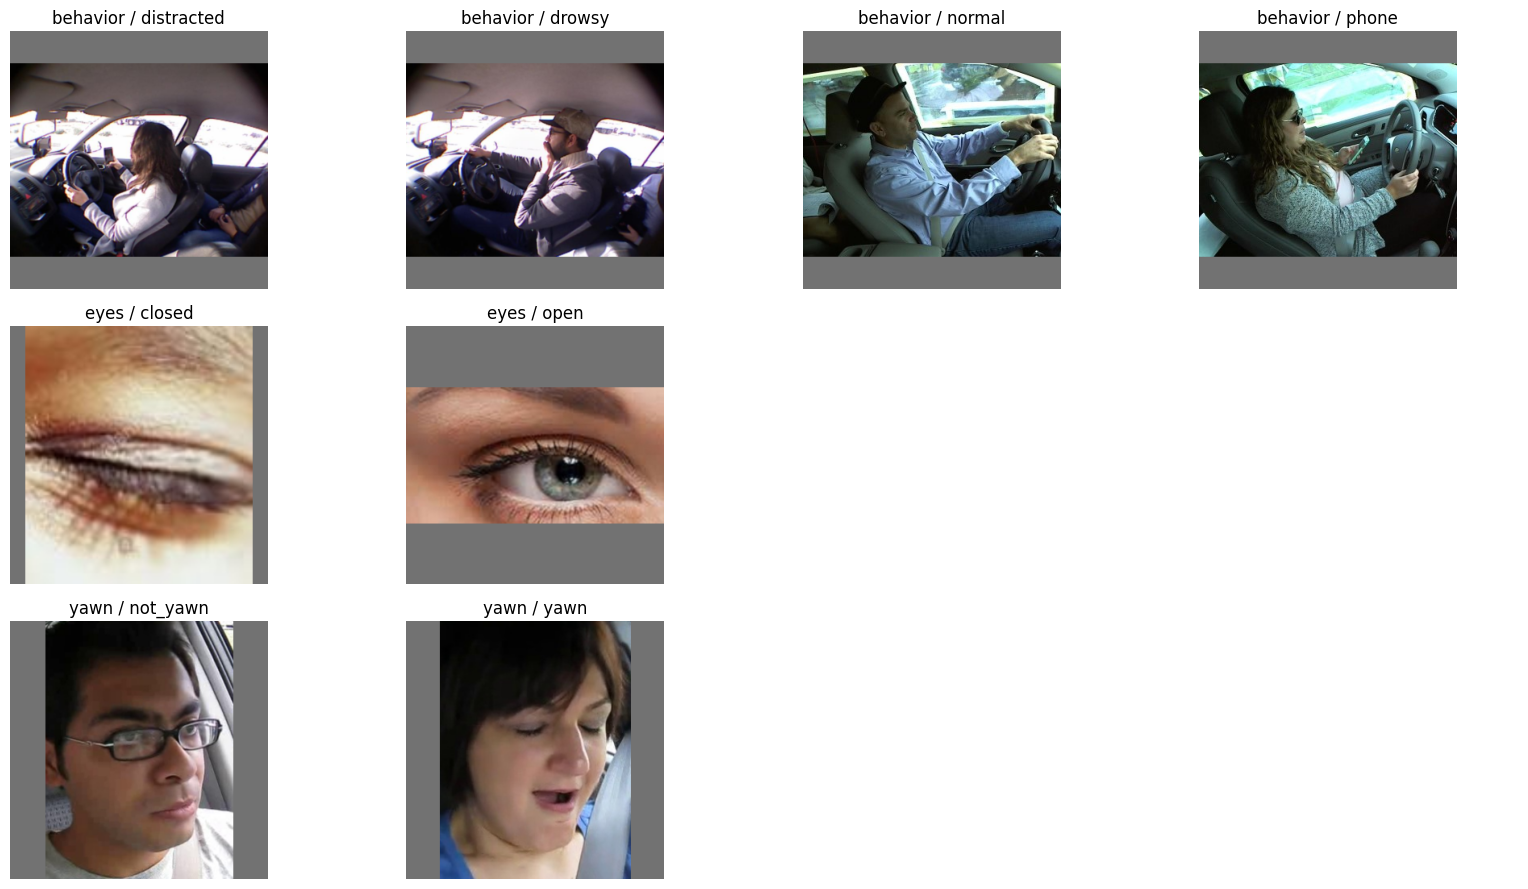

In [8]:
# CELL 8: XEM ẢNH MẪU TRƯỚC KHI TRAIN
# Mục đích: Hiển thị ảnh sau chuẩn hóa để kiểm tra nhãn và vùng mặt.
# Kết quả: Lưới ảnh mẫu của ba nhánh.


import matplotlib.pyplot as plt
n_rows = len(task_frames)
n_cols = max(len(TASKS[task]) for task in task_frames)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows), squeeze=False)
for row, (task, frame) in enumerate(task_frames.items()):
    for col, label in enumerate(TASKS[task]):
        sample = frame[(frame.split == 'train') & (frame.label == label)].sample(1, random_state=SEED).iloc[0]
        with Image.open(sample.prepared_path) as im:
            axes[row, col].imshow(im)
        axes[row, col].set_title(task + ' / ' + label)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Cell 9. Dataset và augmentation

**Làm gì:** Định nghĩa cách nạp ảnh, augmentation và Trainer/Validator cơ sở.

**Đầu ra:** Các class dùng khi train; cell này chưa huấn luyện model.

Chỉ train có augmentation. Validation giữ preprocessing xác định; checkpoint chọn theo macro-F1.
Cache ảnh uint8 được giới hạn bởi RAM và /dev/shm, có đường lui đọc file. Augmentation theo batch chỉ dùng cho train, không dùng khi validation/test.


In [9]:
# CELL 9: DATASET, CACHE RAM VÀ AUGMENTATION THEO BATCH
# Mục đích: Nạp ảnh uint8 có cache giới hạn; chuyển augmentation sang thiết bị train.
# Kết quả: DMSDataset, DMSValidator và DMSTrainer; chưa huấn luyện model.

from concurrent.futures import ThreadPoolExecutor
import gc
import math
import psutil
import torch.nn.functional as F

_IMAGE_RAM_CACHE = {}
_IMAGE_RAM_CACHE_BYTES = 0


def clear_image_ram_cache():
    global _IMAGE_RAM_CACHE_BYTES
    _IMAGE_RAM_CACHE.clear()
    _IMAGE_RAM_CACHE_BYTES = 0
    gc.collect()


def read_resized_rgb(path, size):
    # Prepared images already have the same padding used on Pi. Keep PIL's
    # bilinear resize identical in cache, uncached loading and evaluation.
    with Image.open(path) as image:
        image = image.convert('RGB').resize((size, size), Image.Resampling.BILINEAR)
        return torch.from_numpy(np.array(image, dtype=np.uint8, copy=True)).permute(2, 0, 1)


def shared_image_cache(paths, size, workers):
    global _IMAGE_RAM_CACHE_BYTES
    if not CACHE_IMAGES_RAM:
        return None
    signature = hashlib.sha256('\n'.join(map(str, paths)).encode()).hexdigest()
    key = (signature, int(size))
    if key in _IMAGE_RAM_CACHE:
        return _IMAGE_RAM_CACHE[key]
    needed = len(paths) * 3 * int(size) ** 2  # uint8, never float32 dataset copies
    available = psutil.virtual_memory().available
    budget = min(int(CACHE_MAX_GB * 1024 ** 3), int(available * CACHE_RAM_FRACTION))
    if _IMAGE_RAM_CACHE_BYTES + needed > budget:
        print(f'RAM cache skipped: needs {needed / 1024**3:.2f} GiB; '
              f'budget {budget / 1024**3:.2f} GiB. Using image files.', flush=True)
        return None
    shared = workers > 0
    if shared and os.name != 'nt' and Path('/dev/shm').exists():
        shm = os.statvfs('/dev/shm')
        if needed > .65 * shm.f_bavail * shm.f_frsize:
            print('RAM cache skipped: insufficient /dev/shm for shared workers.', flush=True)
            return None
    try:
        cache = torch.empty((len(paths), 3, size, size), dtype=torch.uint8)
        if shared:
            cache.share_memory_()  # workers share one immutable buffer, including spawn
    except (RuntimeError, MemoryError, OSError) as error:
        print(f'RAM cache unavailable: {type(error).__name__}; using image files.', flush=True)
        return None
    print(f'Caching {len(paths)} resized images: {needed / 1024**3:.2f} GiB uint8 RAM', flush=True)
    # executor.map preserves sample order; only a few decoded images are live.
    with ThreadPoolExecutor(max_workers=max(1, min(8, workers or 2))) as pool:
        for start in range(0, len(paths), 128):
            for offset, pixels in enumerate(pool.map(lambda path: read_resized_rgb(path, size),
                                                     paths[start:start + 128])):
                cache[start + offset].copy_(pixels)
    _IMAGE_RAM_CACHE[key] = cache
    _IMAGE_RAM_CACHE_BYTES += needed
    return cache


def seed_loader_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    random.seed(seed)
    np.random.seed(seed)
    torch.set_num_threads(1)
    cv2.setNumThreads(0)


def fast_loader(dataset, batch_size, workers, device, sampler=None, seed=42):
    options = dict(batch_size=min(int(batch_size), len(dataset)), sampler=sampler,
                   shuffle=False, num_workers=max(0, int(workers)),
                   pin_memory=torch.device(device).type == 'cuda',
                   generator=torch.Generator().manual_seed(seed))
    if workers > 0:
        options.update(persistent_workers=True, prefetch_factor=PREFETCH_FACTOR,
                       worker_init_fn=seed_loader_worker)
    return DataLoader(dataset, **options)


@torch.no_grad()
def augment_image_batch(images, task):
    """Independent per-image augmentation on CUDA; same math on CPU for checks."""
    n = images.shape[0]
    device = images.device
    # Geometric transforms preserve the whole frame and never flip phone hands.
    angles = (torch.rand(n, device=device) * 2 - 1) * math.radians(5)
    scales = .96 + .08 * torch.rand(n, device=device)
    theta = torch.zeros((n, 2, 3), device=device)
    theta[:, 0, 0] = angles.cos() / scales
    theta[:, 0, 1] = -angles.sin() / scales
    theta[:, 1, 0] = angles.sin() / scales
    theta[:, 1, 1] = angles.cos() / scales
    theta[:, :, 2] = (torch.rand((n, 2), device=device) * 2 - 1) * .04
    if task == 'eyes':
        flip = torch.where(torch.rand(n, device=device) < .5, -1., 1.)
        theta[:, 0, :2] *= flip[:, None]
    grid = F.affine_grid(theta, images.shape, align_corners=False)
    fill = 114 / 255
    images = F.grid_sample(images - fill, grid, mode='bilinear', padding_mode='zeros',
                           align_corners=False) + fill
    brightness = .8 + .4 * torch.rand((n, 1, 1, 1), device=device)
    contrast = .8 + .4 * torch.rand((n, 1, 1, 1), device=device)
    saturation = .8 + .4 * torch.rand((n, 1, 1, 1), device=device)
    mean = images.mean(dim=(1, 2, 3), keepdim=True)
    images = ((images - mean) * contrast + mean) * brightness
    gray = images[:, :1] * .2989 + images[:, 1:2] * .587 + images[:, 2:3] * .114
    saturation = torch.where(torch.rand((n, 1, 1, 1), device=device) < .05,
                             torch.zeros_like(saturation), saturation)
    return ((images - gray) * saturation + gray).clamp_(0, 1)


class DMSDataset(ClassificationDataset):
    def __init__(self, root, args, augment=False, prefix='', names=None):
        inherited_args = copy(args)
        inherited_args.cache = False  # 8.4.49 disables its own RAM cache; use bounded cache above
        kw = dict(root=root, args=inherited_args, augment=augment, prefix=prefix)
        if 'names' in inspect.signature(ClassificationDataset).parameters:
            kw['names'] = names
        super().__init__(**kw)
        self.image_size = int(args.imgsz)
        self.torch_transforms = T.Compose([
            T.Resize((self.image_size, self.image_size), interpolation=T.InterpolationMode.BILINEAR),
            T.ToTensor(),
        ])
        self.rgb_cache = shared_image_cache([sample[0] for sample in self.samples],
                                            self.image_size, int(args.workers))

    def __getitem__(self, i):
        pixels = (self.rgb_cache[i] if self.rgb_cache is not None
                  else read_resized_rgb(self.samples[i][0], self.image_size))
        return {'img': pixels, 'cls': self.samples[i][1]}


class DMSValidator(ClassificationValidator):
    def build_dataset(self, img_path):
        return DMSDataset(img_path, self.args, augment=False, prefix=self.args.split,
                          names=getattr(self, 'names', None))

    def preprocess(self, batch):
        uint8_input = batch['img'].dtype == torch.uint8
        batch = super().preprocess(batch)
        if uint8_input:
            batch['img'].div_(255)
        return batch

    def get_stats(self):
        stats = super().get_stats()
        y = torch.cat(self.targets).cpu().numpy().reshape(-1)
        p = torch.cat(self.pred).cpu().numpy()[:, 0]
        macro = float(f1_score(y, p, labels=list(range(len(CLASSES))), average='macro', zero_division=0))
        stats['metrics/macro_f1'] = macro
        stats['metrics/balanced_accuracy'] = float(balanced_accuracy_score(y, p))
        stats['fitness'] = macro
        return stats


def choose_profiled_batch(rows, memory_limit):
    valid = [row for row in rows if row.get('status') == 'ok'
             and row['peak_bytes'] <= memory_limit and row['images_per_second'] > 0]
    if not valid:
        return None
    fastest = max(row['images_per_second'] for row in valid)
    # Pick the smallest batch within 5% of peak throughput, preserving more
    # optimizer updates instead of consuming VRAM with no measurable speed gain.
    return min(row['batch'] for row in valid if row['images_per_second'] >= .95 * fastest)


class DMSTrainer(ClassificationTrainer):
    def build_dataset(self, img_path, mode='train', batch=None):
        return DMSDataset(img_path, self.args, augment=mode == 'train', prefix=mode,
                          names=self.data.get('names'))

    def get_dataloader(self, dataset_path, batch_size=16, rank=-1, mode='train'):
        if rank not in {-1, 0}:
            raise ValueError('This notebook supports a single GPU.')
        dataset = self.build_dataset(dataset_path, mode)
        loader = fast_loader(dataset, batch_size, self.args.workers, self.device, seed=self.args.seed)
        if mode != 'train':
            self.model.transforms = dataset.torch_transforms
        return loader

    def preprocess_batch(self, batch):
        uint8_input = batch['img'].dtype == torch.uint8
        batch = super().preprocess_batch(batch)
        batch['img'] = batch['img'].float()
        if uint8_input:
            batch['img'].div_(255)
        batch['img'] = augment_image_batch(batch['img'], ACTIVE_TASK)
        if self.device.type == 'cuda':
            batch['img'] = batch['img'].contiguous(memory_format=torch.channels_last)
        return batch

    def auto_batch(self, max_num_obj=0, dataset_size=0):
        if self.device.type != 'cuda':
            return 16
        from copy import deepcopy
        train_count = len(ACTIVE_FRAMES[ACTIVE_FRAMES.split.eq('train')])
        # Small eye/yawn datasets need enough parameter updates each epoch.
        cap = min(MAX_GPU_BATCH, max(32, train_count // MIN_STEPS_PER_EPOCH))
        candidates = [batch for batch in (16, 32, 64, 128, 256, 512)
                      if batch <= cap and batch <= train_count]
        free, total = torch.cuda.mem_get_info(self.device)
        baseline = torch.cuda.memory_allocated(self.device)
        memory_limit = min(int(total * GPU_MEMORY_TARGET), baseline + int(free * .85))
        rows = []
        probe = deepcopy(self.model).to(self.device).float().train()
        if self.device.type == 'cuda':
            probe.to(memory_format=torch.channels_last)
        optimizer = torch.optim.AdamW([p for p in probe.parameters() if p.requires_grad], lr=1e-5)
        scaler = torch.amp.GradScaler('cuda', enabled=self.amp)
        x = y = loss = logits = None
        try:
            for batch in candidates:
                try:
                    torch.cuda.reset_peak_memory_stats(self.device)
                    x = torch.rand((batch, 3, self.args.imgsz, self.args.imgsz), device=self.device)
                    y = torch.zeros(batch, dtype=torch.long, device=self.device)
                    durations = []
                    for step in range(4):
                        optimizer.zero_grad(set_to_none=True)
                        torch.cuda.synchronize(self.device)
                        started = time.perf_counter()
                        with torch.autocast('cuda', enabled=self.amp):
                            logits = probe(augment_image_batch(x, ACTIVE_TASK).contiguous(memory_format=torch.channels_last))
                            loss = F.cross_entropy(logits, y)
                        scaler.scale(loss).backward()
                        scaler.step(optimizer)
                        scaler.update()
                        torch.cuda.synchronize(self.device)
                        if step:
                            durations.append(time.perf_counter() - started)
                    peak = torch.cuda.max_memory_allocated(self.device)
                    rows.append(dict(batch=batch, status='ok', peak_bytes=peak,
                                     images_per_second=batch / float(np.median(durations))))
                    if peak >= memory_limit:
                        break
                except torch.cuda.OutOfMemoryError:
                    rows.append(dict(batch=batch, status='oom', peak_bytes=0, images_per_second=0.))
                    break
                finally:
                    x = y = loss = logits = None
                    optimizer.zero_grad(set_to_none=True)
                    torch.cuda.empty_cache()
        finally:
            del optimizer, probe, scaler
            gc.collect()
            torch.cuda.empty_cache()
        pd.DataFrame(rows).to_csv(self.save_dir / 'batch_profile.csv', index=False)
        selected = choose_profiled_batch(rows, memory_limit)
        if selected is None:
            raise RuntimeError('No profiled batch fits the GPU budget. Lower imgsz or MAX_GPU_BATCH.')
        print(f'GPU batch profile: selected {selected}, cap={cap}, target={GPU_MEMORY_TARGET:.0%}', flush=True)
        print(pd.DataFrame(rows).to_string(index=False), flush=True)
        # Account for the selected physical batch in optimizer decay/accumulation.
        self.args.nbs = max(64, selected)
        return selected

    def get_validator(self):
        self.loss_names = ['loss']
        return DMSValidator(self.test_loader, self.save_dir, args=copy(self.args), _callbacks=self.callbacks)


## Cell 10. Cách suy luận và tính điểm

**Làm gì:** Khai báo suy luận PyTorch/ONNX và tính accuracy, macro-F1, confusion matrix.

**Đầu ra:** Các hàm dự đoán và báo cáo; chưa chấm test.

Ảnh mất mặt tính unknown trong mẫu số F1/accuracy, tránh chỉ báo cáo các ảnh dễ xử lý.

In [10]:
# CELL 10: CÁCH SUY LUẬN VÀ TÍNH ĐIỂM
# Mục đích: Khai báo suy luận PyTorch/ONNX và tính accuracy, macro-F1, confusion matrix.
# Kết quả: Các hàm dự đoán và báo cáo; chưa chấm test.


# Đọc ảnh đánh giá theo đúng thứ tự và preprocessing.
class EvaluationImages(Dataset):

    def __init__(self, frame, size):
        self.frame = frame.reset_index(drop=True)
        self.transform = T.Compose([T.Resize((size, size), interpolation=T.InterpolationMode.BILINEAR), T.ToTensor()])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        r = self.frame.iloc[i]
        with Image.open(r.prepared_path) as im:
            x = self.transform(im.convert('RGB'))
        return (x, CLASSES.index(r.label))

# Lấy xác suất từng lớp từ checkpoint PyTorch hoặc ONNX.
def predict_frame(model_path, frame, size, device='cpu', batch=32):
    """Tensor input bypasses the stock crop transform, including ONNX/TFLite."""
    wrapper = YOLO(str(model_path), task='classify')
    inference_device = torch.device(f'cuda:{device}' if isinstance(device, int) else device)
    loader = fast_loader(EvaluationImages(frame, size), batch, min(NUM_WORKERS, 4), inference_device, seed=SEED)
    probabilities, labels = ([], [])
    if Path(model_path).suffix == '.pt':
        model = wrapper.model.to(device).float().eval()
        with torch.inference_mode():
            for x, y in loader:
                out = model(x.to(device, non_blocking=inference_device.type == 'cuda'))
                out = out[0] if isinstance(out, (tuple, list)) else out
                probabilities.append(out.float().cpu().numpy())
                labels.extend(y.tolist())
        names = model.names
    else:
        loader = DataLoader(EvaluationImages(frame, size), batch_size=1, num_workers=0)
        names = None
        for x, y in loader:
            result = wrapper.predict(x, device=device, imgsz=size, verbose=False)[0]
            probabilities.append(result.probs.data.cpu().numpy()[None, :])
            labels.extend(y.tolist())
            names = result.names
    assert [names[i] for i in range(len(CLASSES))] == CLASSES, 'Class order mismatch.'
    return (np.asarray(labels), np.concatenate(probabilities))

# Lưu accuracy, macro-F1, confusion matrix và thống kê lỗi.
def score_predictions(y, probabilities, frame, report_dir, bootstrap=400):
    report_dir = Path(report_dir)
    report_dir.mkdir(parents=True, exist_ok=True)
    p = probabilities.argmax(axis=1)
    summary = dict(accuracy=float(accuracy_score(y, p)), macro_f1=float(f1_score(y, p, labels=range(len(CLASSES)), average='macro', zero_division=0)), balanced_accuracy=float(balanced_accuracy_score(y, p)), n=len(y))
    report = classification_report(y, p, labels=list(range(len(CLASSES))), target_names=CLASSES, output_dict=True, zero_division=0)
    pd.DataFrame(report).transpose().to_csv(report_dir / 'classification_report.csv')
    cm = confusion_matrix(y, p, labels=list(range(len(CLASSES))))
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(report_dir / 'confusion_matrix.csv')
    results = frame.reset_index(drop=True).copy()
    results['prediction'] = [CLASSES[i] for i in p]
    results['confidence'] = probabilities.max(axis=1)
    for i, label in enumerate(CLASSES):
        results[f'p_{label}'] = probabilities[:, i]
    results.to_csv(report_dir / 'predictions.csv', index=False)
    results[results.label != results.prediction].to_csv(report_dir / 'errors.csv', index=False)
    if bootstrap and 'group_id' in results:
        groups = results.group_id.to_numpy()
        unique = np.unique(groups)
        rng = np.random.default_rng(2026)
        values = []
        members = {g: np.flatnonzero(groups == g) for g in unique}
        for _ in range(bootstrap):
            ix = np.concatenate([members[g] for g in rng.choice(unique, len(unique), replace=True)])
            if len(np.unique(y[ix])) == len(CLASSES):
                values.append(f1_score(y[ix], p[ix], labels=range(len(CLASSES)), average='macro', zero_division=0))
        if values:
            summary['macro_f1_group_bootstrap_95ci'] = np.quantile(values, [0.025, 0.975]).tolist()
            summary['bootstrap_valid_resamples'] = len(values)
    for col in ['source', 'subtype', 'subject_id']:
        breakdown = []
        for key, sub in results.groupby(col):
            breakdown.append(dict(group=key, n=len(sub), accuracy=float((sub.label == sub.prediction).mean())))
        pd.DataFrame(breakdown).to_csv(report_dir / f'{col}_breakdown.csv', index=False)
    write_json(report_dir / 'summary.json', summary)
    return summary

# Tính điểm cả ảnh không có mặt bằng dự đoán unknown.
def unit_scores(frames, probabilities, segments, report_dir=None, min_face_coverage=0.3):
    """Evaluate yawn images including missing faces, INCLUDING failed/no-face inputs."""
    labels = TASKS[ACTIVE_TASK]
    rows = []
    for seg in segments.to_dict('records'):
        positions = np.flatnonzero(frames.segment_id.to_numpy() == seg['segment_id'])
        if not len(positions) and pd.notna(seg.get('face_pixel_hash')):
            positions = np.flatnonzero(frames.pixel_hash.to_numpy() == seg['face_pixel_hash'])
        coverage = float(seg['valid_face_frames']) / max(int(seg['requested_frames']), 1)
        eligible = len(positions) > 0 and coverage >= min_face_coverage
        if eligible:
            prob = probabilities[positions].mean(axis=0)
            predicted = int(prob.argmax())
        else:
            prob, predicted = (np.zeros(len(labels)), -1)
        rows.append({**seg, 'prediction': labels[predicted] if predicted >= 0 else 'unknown', 'predicted_index': predicted, 'truth_index': labels.index(seg['label']), 'coverage': coverage, 'confidence': float(prob.max())})
    out = pd.DataFrame(rows)
    if out.empty:
        raise ValueError('No annotated segments for this split.')
    y, p = (out.truth_index.to_numpy(), out.predicted_index.to_numpy())
    summary = dict(accuracy=float(accuracy_score(y, p)), macro_f1=float(f1_score(y, p, labels=list(range(len(labels))), average='macro', zero_division=0)), units=len(out), unknown_units=int((p < 0).sum()), evaluable_fraction=float((p >= 0).mean()), min_face_coverage=min_face_coverage, metric_unit='image' if ACTIVE_TASK == 'eyes' or ('metric_unit' in segments and segments.metric_unit.eq('image').all()) else 'annotated_segment', evaluation_protocols=sorted(segments.evaluation_protocol.unique()), subject_independent=bool(ACTIVE_SEGMENTS[ACTIVE_SEGMENTS.task == ACTIVE_TASK].subject_id.ne('').all()))
    if report_dir:
        report_dir = Path(report_dir)
        report_dir.mkdir(parents=True, exist_ok=True)
        out.to_csv(report_dir / 'unit_predictions.csv', index=False)
        report = classification_report(y, p, labels=list(range(len(labels))), target_names=labels, zero_division=0, output_dict=True)
        pd.DataFrame(report).T.to_csv(report_dir / 'unit_classification_report.csv')
        cm = confusion_matrix(y, p, labels=[*range(len(labels)), -1])
        pd.DataFrame(cm, index=[*labels, 'unknown'], columns=[*labels, 'unknown']).to_csv(report_dir / 'unit_confusion_matrix.csv')
        write_json(report_dir / 'unit_summary.json', summary)
    return summary

## Cell 11. Quy trình train từng nhánh

**Làm gì:** Định nghĩa cân bằng mẫu, chạy các ứng viên và lấy đúng best.pt của từng lần train.

**Đầu ra:** TaskTrainer, TaskValidator, train_task và evaluate; chưa bắt đầu train.

In [11]:
# CELL 11: QUY TRÌNH TRAIN TỪNG NHÁNH
# Mục đích: Định nghĩa cân bằng mẫu, chạy các ứng viên và lấy đúng best.pt của từng lần train.
# Kết quả: TaskTrainer, TaskValidator, train_task và evaluate; chưa bắt đầu train.


# Đánh giá theo nhánh hiện tại, gồm các ảnh mất ROI.
class TaskValidator(DMSValidator):

    def get_dataloader(self, dataset_path, batch_size):
        return fast_loader(self.build_dataset(dataset_path), batch_size, self.args.workers, self.device, seed=self.args.seed)

    def init_metrics(self, model):
        super().init_metrics(model)
        self.all_probabilities = []

    def update_metrics(self, preds, batch):
        super().update_metrics(preds, batch)
        self.all_probabilities.append(preds.detach().float().cpu().numpy())

    def get_stats(self):
        stats = super().get_stats()
        if 'drowsy' in CLASSES:
            y = torch.cat(self.targets).cpu().numpy().reshape(-1)
            p = torch.cat(self.pred).cpu().numpy()[:, 0]
            index = CLASSES.index('drowsy')
            tp = int(((y == index) & (p == index)).sum())
            stats['metrics/drowsy_precision'] = tp / max(int((p == index).sum()), 1)
            stats['metrics/drowsy_recall'] = tp / max(int((y == index).sum()), 1)
        if ACTIVE_TASK == 'yawn':
            order = [str(Path(s[0]).resolve()) for s in self.dataloader.dataset.samples]
            aligned = ACTIVE_FRAMES.set_index('prepared_path').loc[order].reset_index()
            segments = ACTIVE_SEGMENTS[(ACTIVE_SEGMENTS.task == ACTIVE_TASK) & (ACTIVE_SEGMENTS.split == 'val')]
            metric = unit_scores(aligned, np.concatenate(self.all_probabilities), segments)
            stats['metrics/macro_f1'] = metric['macro_f1']
            stats['fitness'] = metric['macro_f1']
        return stats

# Cân bằng lớp/nguồn/nhóm ảnh trong từng nhánh.
def behavior_sampling_weights(aligned, alpha=.5):
    """Class mass n**(1-alpha); equal source and driver mass within each class."""
    class_count = aligned.groupby('label').label.transform('size')
    n_sources = aligned.groupby('label').source.transform('nunique')
    n_subjects = aligned.groupby(['label', 'source']).subject_id.transform('nunique')
    n_images = aligned.groupby(['label', 'source', 'subject_id']).label.transform('size')
    if aligned.subject_id.fillna('').eq('').any():
        raise ValueError('Behavior sampling requires verified subject IDs.')
    return class_count.astype(float).pow(1 - alpha) / (n_sources * n_subjects * n_images)


class TaskTrainer(DMSTrainer):
    def get_dataloader(self, dataset_path, batch_size=16, rank=-1, mode='train'):
        if mode != 'train':
            return super().get_dataloader(dataset_path, batch_size, rank, mode)
        dataset = self.build_dataset(dataset_path, mode)
        path_map = ACTIVE_FRAMES.set_index('prepared_path')
        aligned = path_map.loc[[str(Path(sample[0]).resolve()) for sample in dataset.samples]]
        if ACTIVE_TASK == 'behavior':
            raw_weights = behavior_sampling_weights(aligned, BEHAVIOR_BALANCE_ALPHA)
        else:
            unit = 'group_id' if ACTIVE_TASK == 'eyes' else 'segment_id'
            count = aligned.groupby(['label', unit]).label.transform('size')
            n_units = aligned.groupby('label')[unit].transform('nunique')
            raw_weights = 1 / (count * n_units)
        weights = torch.as_tensor(raw_weights.to_numpy(copy=True), dtype=torch.double)
        if not torch.isfinite(weights).all() or (weights <= 0).any():
            raise ValueError('Invalid sampler weights.')
        audit = aligned[['label', 'source', 'subject_id']].copy()
        audit['draw_probability'] = weights.numpy() / float(weights.sum())
        audit = audit.groupby('label').agg(images=('label', 'size'),
                                         expected_fraction=('draw_probability', 'sum'))
        audit['expected_draws'] = audit.expected_fraction * len(aligned)
        audit['mean_repeats_per_image'] = audit.expected_draws / audit.images
        audit.to_csv(self.save_dir / 'sampler_expected_counts.csv')
        print('Sampling distribution (train only):\n' + audit.to_string(), flush=True)
        generator = torch.Generator().manual_seed(self.args.seed)
        sampler = WeightedRandomSampler(weights, len(aligned), replacement=True, generator=generator)
        return fast_loader(dataset, batch_size, self.args.workers, self.device,
                           sampler=sampler, seed=self.args.seed)

    def get_validator(self):
        self.loss_names = ['loss']
        return TaskValidator(self.test_loader, self.save_dir, args=copy(self.args), _callbacks=self.callbacks)

def record_epoch_start(trainer):
    trainer._epoch_started = time.perf_counter()
    if trainer.device.type == 'cuda':
        torch.cuda.synchronize(trainer.device)
        torch.cuda.reset_peak_memory_stats(trainer.device)


def record_epoch_performance(trainer):
    if getattr(trainer, '_performance_logged_epoch', -1) >= trainer.epoch:
        return  # Ultralytics also fires this callback during final best.pt validation
    trainer._performance_logged_epoch = trainer.epoch
    elapsed = time.perf_counter() - trainer._epoch_started
    cuda = trainer.device.type == 'cuda'
    row = dict(epoch=trainer.epoch + 1, batch=int(trainer.batch_size),
               seconds_including_validation=elapsed,
               train_images_per_second_including_validation=len(trainer.train_loader.dataset) / elapsed,
               peak_gpu_allocated_gib=torch.cuda.max_memory_allocated(trainer.device) / 1024**3 if cuda else 0.,
               gpu_reserved_gib=torch.cuda.memory_reserved(trainer.device) / 1024**3 if cuda else 0.)
    path = trainer.save_dir / 'performance.csv'
    pd.DataFrame([row]).to_csv(path, mode='a', index=False, header=not path.exists())
    print(f"Performance: batch={row['batch']}, epoch+val={elapsed:.1f}s, "
          f"peak GPU={row['peak_gpu_allocated_gib']:.2f} GiB", flush=True)


# Train các ứng viên và lấy best.pt đúng từ lần chạy hiện tại.
def run_trials(dataset_root, frame, work_root, experiments, epochs=70, workers=2, seed=42, device=0, pretrained=True, extra_train_args=None):
    work_root = Path(work_root)
    rows = []
    val = frame[frame.split == 'val'].reset_index(drop=True)
    for exp in experiments:
        clear_image_ram_cache()
        seed_everything(seed)
        started = time.perf_counter()
        model = YOLO(exp['model'])
        clean_exp = {k: v for k, v in exp.items() if k not in {'lr0', 'dropout', 'weight_decay', 'freeze'}}
        requested_batch = (-1 if device != 'cpu' else 16) if exp['batch'] == 'auto' else int(exp['batch'])
        args = dict(data=str(Path(dataset_root).resolve()), trainer=DMSTrainer, epochs=epochs, patience=8, imgsz=exp['imgsz'], batch=requested_batch, device=device, workers=workers, optimizer='AdamW', lr0=exp.get('lr0', 0.0002), lrf=0.01, weight_decay=exp.get('weight_decay', 0.0005), warmup_epochs=2, warmup_bias_lr=0.0002, cos_lr=True, dropout=exp.get('dropout', 0.15), freeze=exp.get('freeze', 0), nbs=64, seed=seed, deterministic=not FAST_CUDNN, amp=torch.cuda.is_available(), cache=False, close_mosaic=0, plots=False, pretrained=pretrained, project=str(work_root / 'runs'), name=exp['name'], exist_ok=False)
        args.update(extra_train_args or {})
        model.add_callback('on_train_epoch_start', record_epoch_start)
        model.add_callback('on_fit_epoch_end', record_epoch_performance)
        model.train(**args)
        resolved_batch = int(model.trainer.batch_size)
        clean_exp['batch'] = resolved_batch
        best = Path(model.trainer.best).resolve()
        if not best.is_file():
            raise FileNotFoundError(best)
        artifact = work_root / 'candidates' / exp['name']
        artifact.mkdir(parents=True, exist_ok=False)
        shutil.copy2(best, artifact / 'best.pt')
        del model
        clear_image_ram_cache()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        y, prob = predict_frame(artifact / 'best.pt', val, exp['imgsz'], device, batch=min(resolved_batch, 128))
        metrics = score_predictions(y, prob, val, artifact / 'validation', bootstrap=0)
        rows.append(dict(**clean_exp, checkpoint=str((artifact / 'best.pt').resolve()), validation_macro_f1=metrics['macro_f1'], validation_accuracy=metrics['accuracy'], train_minutes=(time.perf_counter() - started) / 60, checkpoint_mb=(artifact / 'best.pt').stat().st_size / 1024 ** 2))
        pd.DataFrame(rows).to_csv(work_root / 'validation_leaderboard.csv', index=False)
    return pd.DataFrame(rows).sort_values('validation_macro_f1', ascending=False).reset_index(drop=True)

# Huấn luyện một nhánh và tạo bảng xếp hạng validation.
def train_task(task, frames, segments, work, experiments, epochs=60, device=0, workers=2, pretrained=True, extra_train_args=None):
    activate(task, frames, segments)
    rows = []
    for exp in experiments:
        args = dict(trainer=TaskTrainer, **extra_train_args or {})
        table = run_trials(Path(work) / task / 'dataset', frames, Path(work) / task, [exp], epochs=epochs, device=device, workers=workers, pretrained=pretrained, extra_train_args=args, seed=(extra_train_args or {}).get('seed', 42))
        row = table.iloc[0].to_dict()
        row['frame_validation_macro_f1'] = row['validation_macro_f1']
        if task == 'yawn':
            val = frames[frames.split == 'val'].reset_index(drop=True)
            _, probs = predict_frame(row['checkpoint'], val, int(row['imgsz']), device)
            score = unit_scores(val, probs, segments[(segments.task == task) & (segments.split == 'val')], Path(row['checkpoint']).parent / 'validation_units')
            row['validation_macro_f1'] = score['macro_f1']
            row['validation_accuracy'] = score['accuracy']
        rows.append(dict(task=task, **row))
        pd.DataFrame(rows).to_csv(Path(work) / task / 'validation_leaderboard.csv', index=False)
    return pd.DataFrame(rows).sort_values('validation_macro_f1', ascending=False).reset_index(drop=True)

# Đánh giá model trên val hoặc test, không dùng test để chọn model.
def evaluate(task, frames, segments, model_path, imgsz, split, output, device='cpu'):
    activate(task, frames, segments)
    data = frames[frames.split == split].reset_index(drop=True)
    y, probs = predict_frame(model_path, data, imgsz, device=device)
    frame_score = score_predictions(y, probs, data, Path(output) / 'frames', bootstrap=0)
    if task in {'behavior', 'eyes'}:
        return {**frame_score, 'metric_unit': 'image'}
    segment = unit_scores(data, probs, segments[(segments.task == task) & (segments.split == split)], Path(output) / 'units')
    return {**segment, 'valid_face_macro_f1': frame_score['macro_f1']}

## Cell 12. Train và khóa lựa chọn

Chạy lần lượt ba nhánh; balanced có bốn ứng viên. GPU tự đo forward/backward và
augmentation với nhiều batch, chọn tốc độ tốt trong ngân sách VRAM 75%; dữ liệu
nhỏ giới hạn batch để giữ số bước học. `batch_profile.csv` ghi phép đo tổng hợp;
`performance.csv` ghi thời gian epoch gồm validation và đỉnh VRAM thực.
`sampler_expected_counts.csv` cho biết mức lặp từng lớp sau cân bằng một phần.
Early stopping vẫn chọn validation macro-F1; drowsy precision/recall được ghi mỗi epoch.
`quick_check` giới hạn hai epoch, không phải báo cáo độ chính xác cuối cùng.


In [12]:
# CELL 12: HUẤN LUYỆN VÀ KHÓA LỰA CHỌN
# Mục đích: Train lần lượt ba nhánh, so sánh validation rồi khóa các model sẽ kiểm tra.
# Kết quả: leaderboards, finalists, weights best.pt và selection_locked.json.


DEVICE = 0 if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cpu' and PROFILE != 'quick_check':
    raise RuntimeError('Đã chuẩn bị dữ liệu xong nhưng chưa có GPU. Bật T4 trong Runtime → Change runtime type, '
                       'hoặc chọn PROFILE=quick_check để thử trên CPU. Full training không tự chuyển sang CPU.')
if DEVICE == 'cpu':
    NUM_WORKERS = 0
    print('Chạy thử trên CPU, tối đa 2 epochs; chưa phải kết quả huấn luyện đầy đủ.')
leaderboards = {}
for task in TASKS:
    leaderboards[task] = train_task(task, task_frames[task], unit_info, WORK, EXPERIMENTS[task], epochs=EPOCHS, workers=NUM_WORKERS, device=DEVICE, extra_train_args=dict(seed=SEED))
    display(leaderboards[task])
    backup_results()

finalists = {}
for task, table in leaderboards.items():
    table = table.assign(resource_proxy=table.checkpoint_mb * table.imgsz ** 2)
    finalists[task] = pd.DataFrame([table.sort_values('validation_macro_f1', ascending=False).iloc[0], table.sort_values('resource_proxy').iloc[0]]).drop_duplicates('name').reset_index(drop=True)
write_json(WORK / 'selection_locked.json', {k: v.to_dict('records') for k, v in finalists.items()})
print('Đã khóa model. Chưa dùng điểm test để chọn model.')

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.49 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dms_v6_20261120_194102_102132/behavior/dataset, degrees=0.0, deterministic=False, device=0, dfl=1.5, dnn=False, dropout=0.3, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=4, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.

,task,name,model,imgsz,batch,checkpoint,validation_macro_f1,validation_accuracy,train_minutes,checkpoint_mb,frame_validation_macro_f1
0,behavior,nano224,yolo11n-cls.pt,224,128,/content/dms_v6_20261120_194102_102132/behavio...,0.554597,0.798282,5.231330,3.044506,0.554597
1,behavior,small224,yolo11s-cls.pt,224,64,/content/dms_v6_20261120_194102_102132/behavio...,0.553837,0.770061,5.842693,10.519360,0.553837


New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.49 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dms_v6_20261120_194102_102132/eyes/dataset, degrees=0.0, deterministic=False, device=0, dfl=1.5, dnn=False, dropout=0.15, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.00015, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0,

,task,name,model,imgsz,batch,checkpoint,validation_macro_f1,validation_accuracy,train_minutes,checkpoint_mb,frame_validation_macro_f1
0,eyes,nano128,yolo11n-cls.pt,128,32,/content/dms_v6_20261120_194102_102132/eyes/ca...,1.0,1.0,0.559881,3.038586,1.0


New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.49 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dms_v6_20261120_194102_102132/yawn/dataset, degrees=0.0, deterministic=False, device=0, dfl=1.5, dnn=False, dropout=0.15, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=160, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, 

,task,name,model,imgsz,batch,checkpoint,validation_macro_f1,validation_accuracy,train_minutes,checkpoint_mb,frame_validation_macro_f1
0,yawn,nano160,yolo11n-cls.pt,160,32,/content/dms_v6_20261120_194102_102132/yawn/ca...,1.0,1.0,0.443611,3.038097,1.0


Đã khóa model. Chưa dùng điểm test để chọn model.


## Cell 13. Xuất ONNX và kiểm tra validation

**Làm gì:** Xuất các model đã chọn, so F1 ONNX với PyTorch rồi khóa export hợp lệ.

**Đầu ra:** ONNX, metadata/checksum và export_selection_locked.json.

Mặc định ONNX FP32 batch 1. Chấp nhận suy giảm tối đa 0,01 macro-F1; không tự bật INT8.

In [13]:
# CELL 13: XUẤT ONNX VÀ KIỂM TRA VALIDATION
# Mục đích: Xuất các model đã chọn, so F1 ONNX với PyTorch rồi khóa export hợp lệ.
# Kết quả: ONNX, metadata/checksum và export_selection_locked.json.


# Chuẩn bị ảnh train cho calibration nếu thử INT8 sau này.
def prepare_calibration(frame, output_root, count_per_class=100, seed=42):
    """Exporters can read val; here BOTH train and val contain TRAIN images only."""
    output_root = Path(output_root)
    if output_root.exists() and any(output_root.iterdir()):
        raise FileExistsError(output_root)
    selected = pd.concat([g.sample(min(count_per_class, len(g)), random_state=seed) for _, g in frame[frame.split == 'train'].groupby('label')])
    if len(selected) < 300:
        raise ValueError('Need at least 300 representative training images for INT8 calibration.')
    for r in selected.itertuples():
        for split in ['train', 'val']:
            dest = output_root / split / r.label / Path(r.prepared_path).name
            dest.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(r.prepared_path, dest)
    selected.to_csv(output_root.parent / 'calibration_manifest.csv', index=False)
    return output_root

# Xuất model và ghi checksum; bản mặc định dùng ONNX FP32.
def export_candidate(row, work_root, calibration_root=None, int8=False):
    """Use returned paths; never search other runs for an arbitrary best*.tflite."""
    from ultralytics.engine.exporter import export_formats
    artifact = Path(row['checkpoint']).parent
    model = YOLO(row['checkpoint'])
    returned = Path(model.export(format='onnx', imgsz=int(row['imgsz']), batch=1, dynamic=False, half=False, simplify=False, opset=17, device='cpu'))
    onnx_path = artifact / 'model.onnx'
    if returned.resolve() != onnx_path.resolve():
        shutil.copy2(returned, onnx_path)
    exports = {'onnx_fp32': str(onnx_path.resolve())}
    if int8:
        formats = export_formats()['Argument']
        kw = dict(imgsz=int(row['imgsz']), batch=1, device='cpu', data=str(calibration_root), fraction=1.0)
        if 'litert' in formats:
            kw.update(format='litert', quantize=8)
        else:
            kw.update(format='tflite', int8=True)
        returned = Path(model.export(**kw))
        if returned.suffix != '.tflite' or not returned.is_file():
            raise RuntimeError(f'Unexpected export output: {returned}')
        dest = artifact / 'model_int8.tflite'
        if returned.resolve() != dest.resolve():
            shutil.copy2(returned, dest)
        exports['tflite_int8'] = str(dest.resolve())
    metadata = dict(classes=CLASSES, base_size=BASE_SIZE, imgsz=int(row['imgsz']), preprocessing='PIL EXIF transpose; RGB; ImageOps.pad to base_size, bilinear, RGB padding 114; resize to imgsz bilinear; float32 /255; NCHW for ONNX', checkpoint_sha256=sha256_file(row['checkpoint']), outputs='softmax probabilities, not independently calibrated confidence', task_limit='Independent behavior, single-eye state, and yawn image tasks; external camera validation required', validation_macro_f1=float(row['validation_macro_f1']), artifacts={k: dict(filename=Path(v).name, sha256=sha256_file(v)) for k, v in exports.items()})
    write_json(artifact / 'metadata.json', metadata)
    return exports

# Bổ sung metadata nhãn, ROI và giới hạn của từng nhánh.
def export(task, row, frames, segments, work, int8=False):
    activate(task, frames, segments)
    calibration = None
    if int8:
        calibration = prepare_calibration(frames, Path(work) / task / ('calibration_' + row['name']), count_per_class=200)
    exports = export_candidate(row, work, calibration_root=calibration, int8=int8)
    path = Path(row['checkpoint']).parent / 'metadata.json'
    metadata = json.loads(path.read_text(encoding='utf-8'))
    metadata.update(task=task, classes=TASKS[task], roi='whole_frame' if task == 'behavior' else 'eyes' if task == 'eyes' else 'face', face_detector='YuNet 2023mar, 320x320 letterbox, confidence 0.7, margin 15%', task_limit='Independent image task outputs. Perceptual clusters do not prove identity independence. Yawn images are not temporal event annotations; validate on new people/camera.', evaluation_protocols=sorted(frames.evaluation_protocol.unique()), subject_independent=bool((frames if task in {'behavior', 'eyes'} else segments[segments.task == task]).subject_id.ne('').all()))
    if task == 'behavior':
        metadata.update(drowsy_label='3MDAD AC12 fatigue and somnolence, action-sequence supervision; not per-frame head-drop or physiological sleep diagnosis', positive_sources=['three_mdad'], sources=sorted(frames.source.unique()))
    if task == 'eyes':
        metadata.update(training_roi='provided_single_eye_crop', camera_roi='two individual YuNet landmark crops; averaged probabilities; missing eye returns unknown', roi_geometry=dict(half_width_intereye=.42, half_height_intereye=.34, min_intereye_px=16, min_crop_side_px=12), temporal_limit='Prolonged confirmed eye closure is a demo alert; head nodding is not a trained class.')
    write_json(path, metadata)
    return exports

export_tables = {}
for task, table in finalists.items():
    rows = []
    for candidate in table.to_dict('records'):
        paths = export(task, candidate, task_frames[task], unit_info, WORK, int8=False)
        for fmt, path in paths.items():
            score = evaluate(task, task_frames[task], unit_info, path, int(candidate['imgsz']), 'val', Path(candidate['checkpoint']).parent / ('validation_' + fmt))
            drop = float(candidate['validation_macro_f1']) - score['macro_f1']
            rows.append(dict(candidate=candidate['name'], format=fmt, path=path, checkpoint=candidate['checkpoint'], imgsz=int(candidate['imgsz']), validation_macro_f1=score['macro_f1'], f1_drop=drop, acceptable=drop <= 0.01))
    export_tables[task] = pd.DataFrame(rows)
    display(export_tables[task])
write_json(WORK / 'export_selection_locked.json', {k: v.to_dict('records') for k, v in export_tables.items()})
for task, table in export_tables.items():
    if not table.acceptable.any():
        raise RuntimeError(f'{task}: ONNX sai lệch quá ngưỡng validation; xem báo cáo export trước khi tiếp tục.')
backup_results()

Ultralytics 8.4.49 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
YOLO11n-cls summary (fused): 47 layers, 1,531,148 parameters, 0 gradients, 3.2 GFLOPs

PyTorch: starting from '/content/dms_v6_20261120_194102_102132/behavior/candidates/nano224/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 4) (3.0 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 0.4s, saved as '/content/dms_v6_20261120_194102_102132/behavior/candidates/nano224/best.onnx' (5.9 MB)

Export complete (0.6s)
Results saved to /content/dms_v6_20261120_194102_102132/behavior/candidates/nano224/best.onnx
Predict:         yolo predict task=classify model=/content/dms_v6_20261120_194102_102132/behavior/candidates/nano224/best.onnx imgsz=224 
Validate:        yolo val task=classify model=/content/dms_v6_20261120_19410

,candidate,format,path,checkpoint,imgsz,validation_macro_f1,f1_drop,acceptable
0,nano224,onnx_fp32,/content/dms_v6_20261120_194102_102132/behavio...,/content/dms_v6_20261120_194102_102132/behavio...,224,0.554597,0.0,True


Ultralytics 8.4.49 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs

PyTorch: starting from '/content/dms_v6_20261120_194102_102132/eyes/candidates/nano128/best.pt' with input shape (1, 3, 128, 128) BCHW and output shape(s) (1, 2) (3.0 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 0.3s, saved as '/content/dms_v6_20261120_194102_102132/eyes/candidates/nano128/best.onnx' (5.9 MB)

Export complete (0.3s)
Results saved to /content/dms_v6_20261120_194102_102132/eyes/candidates/nano128/best.onnx
Predict:         yolo predict task=classify model=/content/dms_v6_20261120_194102_102132/eyes/candidates/nano128/best.onnx imgsz=128 
Validate:        yolo val task=classify model=/content/dms_v6_20261120_194102_102132/eyes/candidates/nano128/best.onnx imgsz=128 data=/content/dms_v6_20261120_194102_102132/eyes/dataset  
Visualize:       https://netron.app
Loading /c

,candidate,format,path,checkpoint,imgsz,validation_macro_f1,f1_drop,acceptable
0,nano128,onnx_fp32,/content/dms_v6_20261120_194102_102132/eyes/ca...,/content/dms_v6_20261120_194102_102132/eyes/ca...,128,1.0,0.0,True


Ultralytics 8.4.49 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs

PyTorch: starting from '/content/dms_v6_20261120_194102_102132/yawn/candidates/nano160/best.pt' with input shape (1, 3, 160, 160) BCHW and output shape(s) (1, 2) (3.0 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 0.3s, saved as '/content/dms_v6_20261120_194102_102132/yawn/candidates/nano160/best.onnx' (5.9 MB)

Export complete (0.4s)
Results saved to /content/dms_v6_20261120_194102_102132/yawn/candidates/nano160/best.onnx
Predict:         yolo predict task=classify model=/content/dms_v6_20261120_194102_102132/yawn/candidates/nano160/best.onnx imgsz=160 
Validate:        yolo val task=classify model=/content/dms_v6_20261120_194102_102132/yawn/candidates/nano160/best.onnx imgsz=160 data=/content/dms_v6_20261120_194102_102132/yawn/dataset  
Visualize:       https://netron.app
Loading /c

,candidate,format,path,checkpoint,imgsz,validation_macro_f1,f1_drop,acceptable
0,nano160,onnx_fp32,/content/dms_v6_20261120_194102_102132/yawn/ca...,/content/dms_v6_20261120_194102_102132/yawn/ca...,160,1.0,0.0,True


## Cell 14. Đánh giá test và chuẩn bị file Pi

**Làm gì:** Chấm toàn bộ test của các lựa chọn đã khóa, rồi chuyển sang thư mục xuất code Pi.

**Đầu ra:** final_test_results.csv, báo cáo từng nhánh và thư mục file Pi.

F1 theo ảnh, chưa phải recall sự kiện theo thời gian. Không gộp ba nhánh hành vi/mắt/ngáp thành một accuracy chung. Sau cell này chạy tiếp ba cell ghi file bên dưới để hoàn tất gói Pi.

Loading /content/dms_v6_20261120_194102_102132/behavior/candidates/nano224/model.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
Loading /content/dms_v6_20261120_194102_102132/eyes/candidates/nano128/model.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
Loading /content/dms_v6_20261120_194102_102132/yawn/candidates/nano160/model.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider


,task,candidate,format,accuracy,macro_f1,balanced_accuracy,n,metric_unit,units,unknown_units,evaluable_fraction,min_face_coverage,evaluation_protocols,subject_independent,valid_face_macro_f1
0,behavior,nano224,pytorch_fp32,0.775644,0.542559,0.505893,4270.0,image,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,behavior,nano224,onnx_fp32,0.775644,0.542559,0.505893,4270.0,image,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,eyes,nano128,pytorch_fp32,0.990868,0.990866,0.990826,219.0,image,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,eyes,nano128,onnx_fp32,0.990868,0.990866,0.990826,219.0,image,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,yawn,nano160,pytorch_fp32,0.982456,0.982435,NaN,NaN,image,228.0,0.0,1.0,0.3,[perceptual_cluster_holdout_subjects_unverified],False,0.982435
5,yawn,nano160,onnx_fp32,0.982456,0.982435,NaN,NaN,image,228.0,0.0,1.0,0.3,[perceptual_cluster_holdout_subjects_unverified],False,0.982435


F1/accuracy theo ảnh; không phải recall sự kiện buồn ngủ/ngáp theo thời gian.


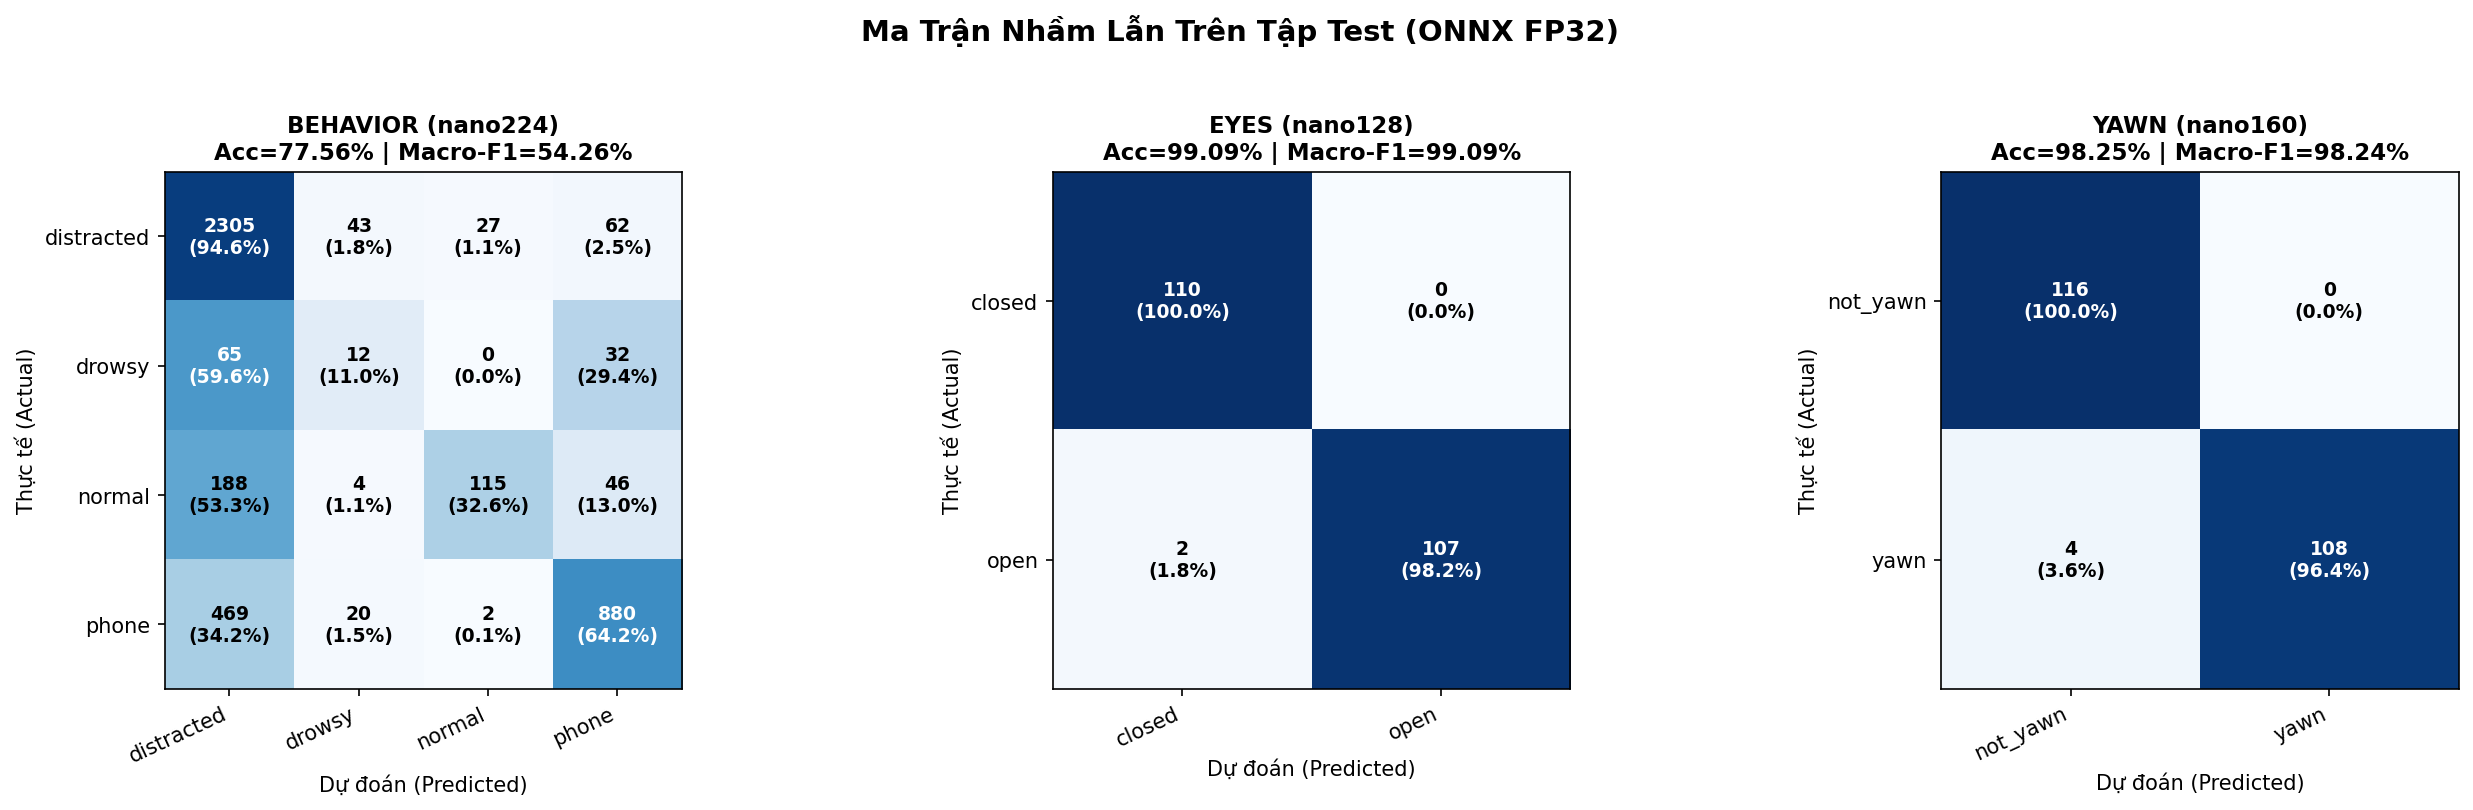

,Task,Model,Class,Precision,Recall,F1,Support
0,behavior,nano224,behavior:distracted,0.761480,0.945835,0.843704,2437
1,behavior,nano224,behavior:drowsy,0.151899,0.110092,0.127660,109
2,behavior,nano224,behavior:normal,0.798611,0.325779,0.462777,353
3,behavior,nano224,behavior:phone,0.862745,0.641867,0.736094,1371
4,eyes,nano128,eyes:closed,0.982143,1.000000,0.990991,110
5,eyes,nano128,eyes:open,1.000000,0.981651,0.990741,109
6,yawn,nano160,yawn:not_yawn,0.966667,1.000000,0.983051,116
7,yawn,nano160,yawn:yawn,1.000000,0.964286,0.981818,112


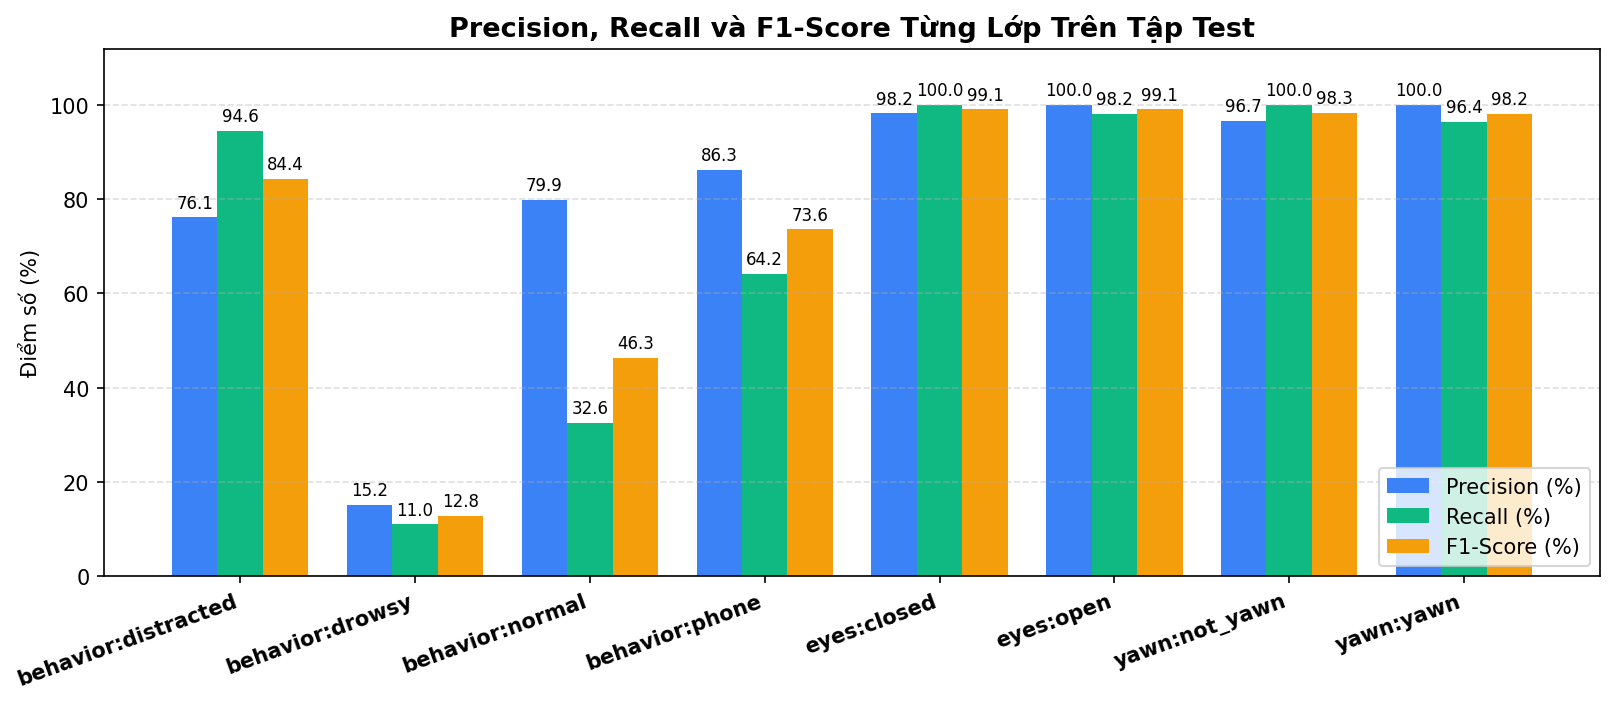

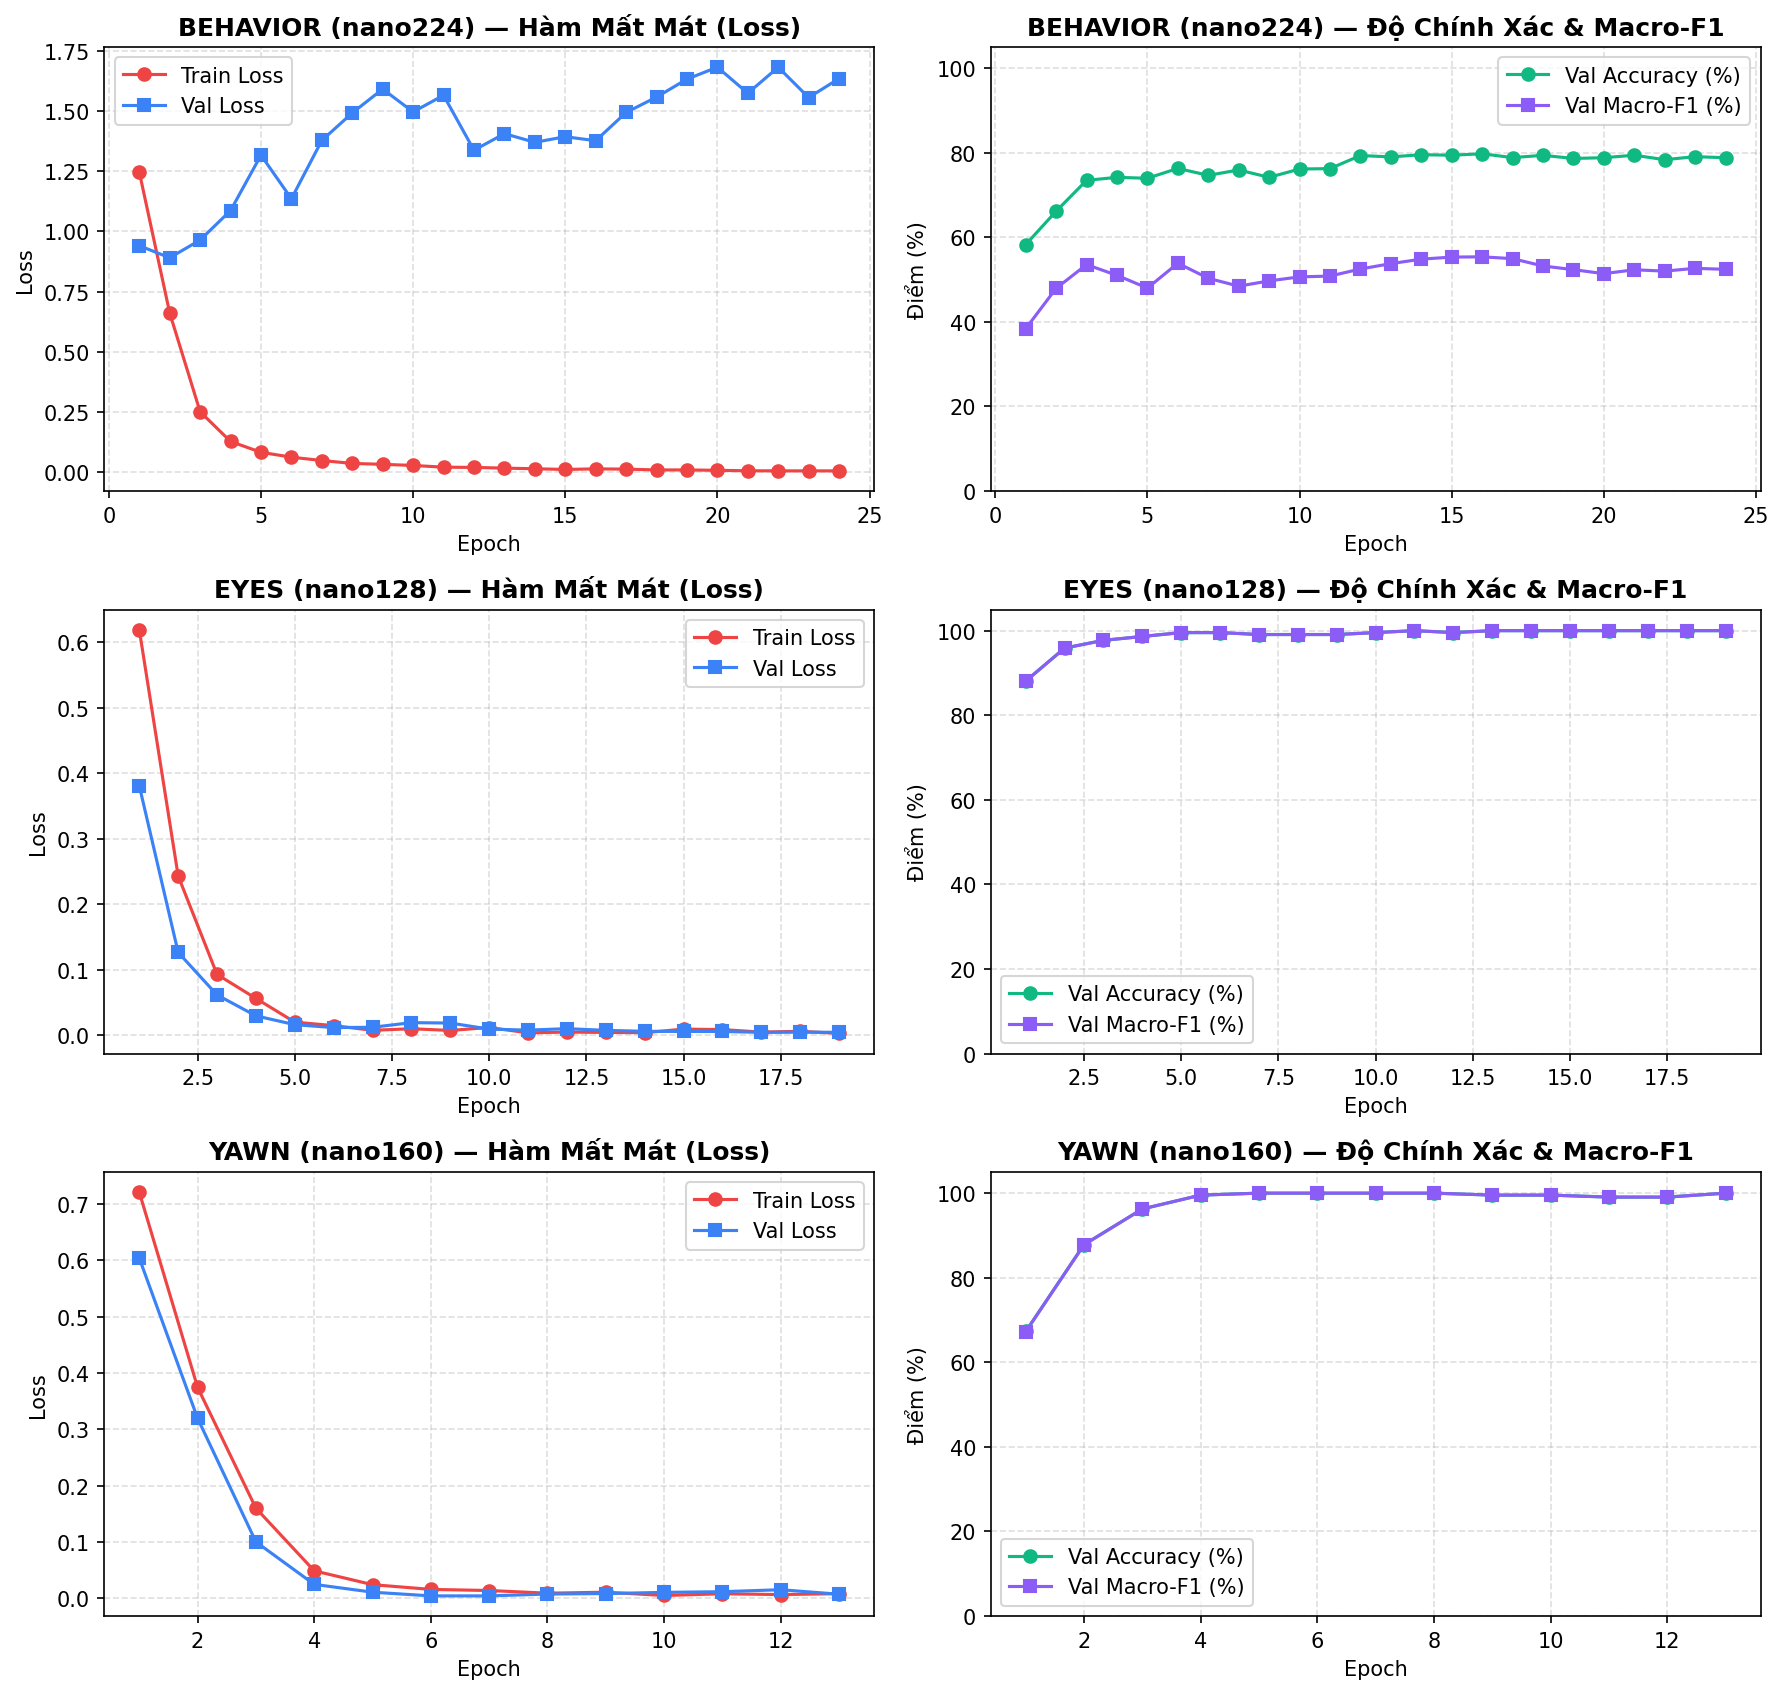

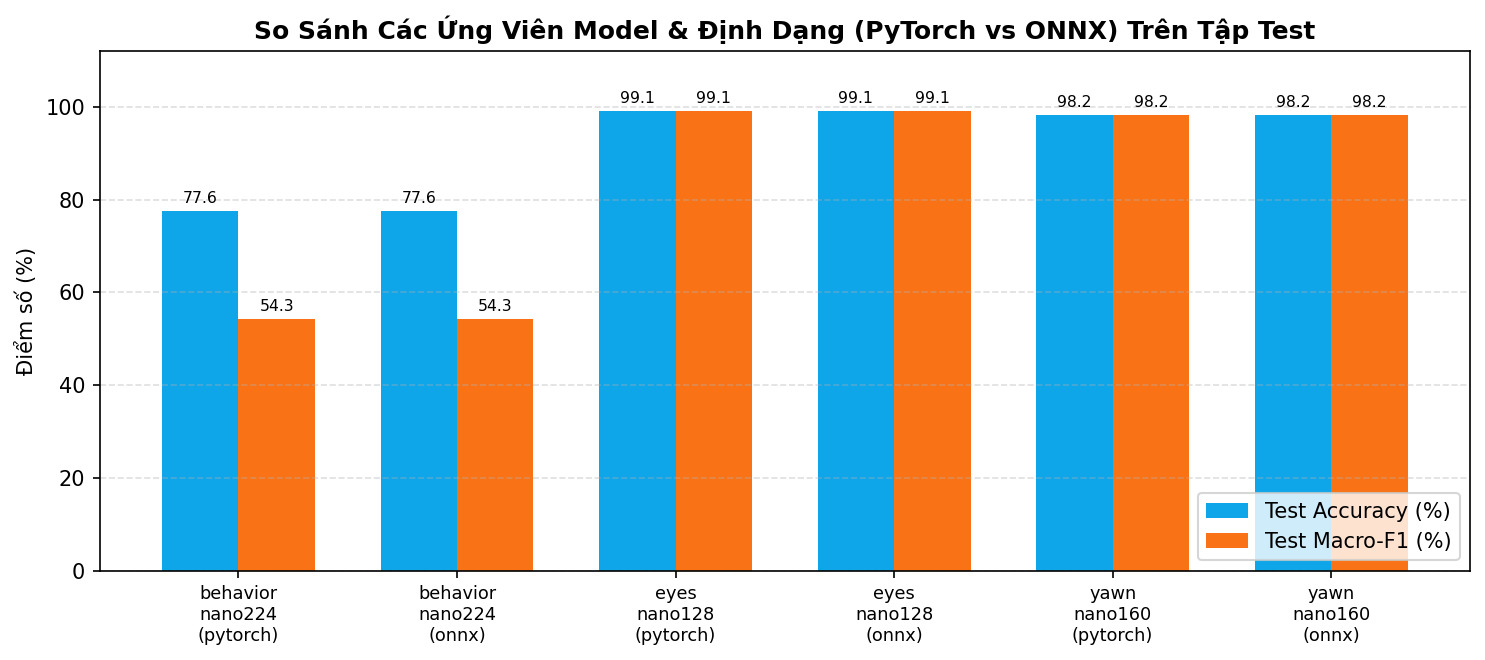

Đã lưu trọn bộ 4 biểu đồ báo cáo (300 DPI) tại: /content/dms_v6_20261120_194102_102132/report_figures


In [14]:
# CELL 14: ĐÁNH GIÁ TEST VÀ CHUẨN BỊ FILE PI
# Mục đích: Chấm toàn bộ test của các lựa chọn đã khóa, rồi chuyển sang thư mục xuất code Pi.
# Kết quả: final_test_results.csv, báo cáo từng nhánh và thư mục file Pi.


test_rows = []
for task, table in finalists.items():
    for candidate in table.to_dict('records'):
        entries = [('pytorch_fp32', candidate['checkpoint'])]
        entries += [(r['format'], r['path']) for r in export_tables[task].to_dict('records') if r['candidate'] == candidate['name'] and r['acceptable']]
        for fmt, path in entries:
            report = WORK / task / 'reports' / candidate['name'] / fmt
            score = evaluate(task, task_frames[task], unit_info, path, int(candidate['imgsz']), 'test', report, device=DEVICE if fmt == 'pytorch_fp32' else 'cpu')
            test_rows.append(dict(task=task, candidate=candidate['name'], format=fmt, **score))
results = pd.DataFrame(test_rows)
results.to_csv(WORK / 'final_test_results.csv', index=False)
display(results)
print('F1/accuracy theo ảnh; không phải recall sự kiện buồn ngủ/ngáp theo thời gian.')

# Tự động vẽ và lưu 4 bộ biểu đồ phục vụ báo cáo (300 DPI PNG)
def generate_report_charts(work_dir, test_df):
    import matplotlib.pyplot as plt
    work_dir = Path(work_dir)
    fig_dir = work_dir / 'report_figures'
    fig_dir.mkdir(parents=True, exist_ok=True)
    onnx_df = test_df[test_df['format'] == 'onnx_fp32']
    selected = {task: table[table.acceptable].sort_values('validation_macro_f1', ascending=False).iloc[0].candidate for task, table in export_tables.items()}
    best_per_task = onnx_df[onnx_df.apply(lambda row: row.candidate == selected[row.task], axis=1)]

    # 1. Ma trận nhầm lẫn (Confusion Matrix) cho 3 nhánh trên tập Test
    fig, axes = plt.subplots(1, len(best_per_task), figsize=(6 * len(best_per_task), 5.2), dpi=150)
    if len(best_per_task) == 1:
        axes = [axes]
    for ax, row in zip(axes, best_per_task.itertuples()):
        base = work_dir / row.task / 'reports' / row.candidate / row.format
        cm_path = base / ('frames/confusion_matrix.csv' if row.task in {'behavior', 'eyes'} else 'units/unit_confusion_matrix.csv')
        if not cm_path.is_file():
            cm_path = base / 'frames/confusion_matrix.csv'
        cm_df = pd.read_csv(cm_path, index_col=0)
        if 'unknown' in cm_df.index and cm_df.loc['unknown'].sum() == 0 and cm_df['unknown'].sum() == 0:
            cm_df = cm_df.drop(index='unknown', columns='unknown')
        cm = cm_df.to_numpy(dtype=float)
        row_sums = cm.sum(axis=1, keepdims=True)
        norm_cm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums > 0) * 100.0
        im = ax.imshow(norm_cm, cmap='Blues', vmin=0, vmax=100)
        ax.set_title(f"{row.task.upper()} ({row.candidate})\nAcc={row.accuracy*100:.2f}% | Macro-F1={row.macro_f1*100:.2f}%", fontsize=11, fontweight='bold')
        ax.set_xticks(range(len(cm_df.columns)))
        ax.set_yticks(range(len(cm_df.index)))
        ax.set_xticklabels(cm_df.columns, rotation=25, ha='right')
        ax.set_yticklabels(cm_df.index)
        ax.set_xlabel('Dự đoán (Predicted)')
        ax.set_ylabel('Thực tế (Actual)')
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                val = int(cm[i, j])
                pct = norm_cm[i, j]
                color = 'white' if pct > 55 else 'black'
                ax.text(j, i, f"{val}\n({pct:.1f}%)", ha='center', va='center', color=color, fontsize=9, fontweight='bold')
    plt.suptitle('Ma Trận Nhầm Lẫn Trên Tập Test (ONNX FP32)', fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    fig.savefig(fig_dir / 'fig1_confusion_matrices.png', dpi=300, bbox_inches='tight')
    plt.show()

    # 2. Biểu đồ Precision / Recall / F1 theo từng lớp (Per-Class Metrics)
    class_rows = []
    for row in best_per_task.itertuples():
        base = work_dir / row.task / 'reports' / row.candidate / row.format
        rep_path = base / ('frames/classification_report.csv' if row.task in {'behavior', 'eyes'} else 'units/unit_classification_report.csv')
        if not rep_path.is_file():
            rep_path = base / 'frames/classification_report.csv'
        rep_df = pd.read_csv(rep_path, index_col=0)
        for cls_name, r in rep_df.iterrows():
            if cls_name in {'accuracy', 'macro avg', 'weighted avg'}:
                continue
            class_rows.append(dict(Task=row.task, Model=row.candidate, Class=f"{row.task}:{cls_name}", Precision=float(r['precision']), Recall=float(r['recall']), F1=float(r['f1-score']), Support=int(r['support'])))
    class_table = pd.DataFrame(class_rows)
    display(class_table)
    class_table.to_csv(fig_dir / 'per_class_test_metrics.csv', index=False)

    fig, ax = plt.subplots(figsize=(11, 4.8), dpi=150)
    x = np.arange(len(class_table))
    w = 0.26
    b1 = ax.bar(x - w, class_table['Precision'] * 100, w, label='Precision (%)', color='#3b82f6')
    b2 = ax.bar(x, class_table['Recall'] * 100, w, label='Recall (%)', color='#10b981')
    b3 = ax.bar(x + w, class_table['F1'] * 100, w, label='F1-Score (%)', color='#f59e0b')
    ax.set_xticks(x)
    ax.set_xticklabels(class_table['Class'], rotation=20, ha='right', fontweight='bold')
    ax.set_ylim(0, 112)
    ax.set_ylabel('Điểm số (%)')
    ax.set_title('Precision, Recall và F1-Score Từng Lớp Trên Tập Test', fontsize=13, fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(loc='lower right')
    for bars in (b1, b2, b3):
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, h + 1.2, f"{h:.1f}", ha='center', va='bottom', fontsize=8)
    plt.tight_layout()
    fig.savefig(fig_dir / 'fig2_per_class_metrics.png', dpi=300, bbox_inches='tight')
    plt.show()

    # 3. Đường cong huấn luyện (Learning Curves: Loss & Val Macro-F1 theo Epoch)
    fig, axes = plt.subplots(len(best_per_task), 2, figsize=(12, 3.8 * len(best_per_task)), dpi=150)
    if len(best_per_task) == 1:
        axes = np.array([axes])
    for idx, row in enumerate(best_per_task.itertuples()):
        csv_path = work_dir / row.task / 'runs' / row.candidate / 'results.csv'
        ax_loss, ax_metric = axes[idx, 0], axes[idx, 1]
        if csv_path.is_file():
            hist = pd.read_csv(csv_path)
            hist.columns = [c.strip() for c in hist.columns]
            ep = hist['epoch']
            if 'train/loss' in hist:
                ax_loss.plot(ep, hist['train/loss'], marker='o', label='Train Loss', color='#ef4444')
            if 'val/loss' in hist:
                ax_loss.plot(ep, hist['val/loss'], marker='s', label='Val Loss', color='#3b82f6')
            ax_loss.set_title(f"{row.task.upper()} ({row.candidate}) — Hàm Mất Mát (Loss)", fontweight='bold')
            ax_loss.set_xlabel('Epoch')
            ax_loss.set_ylabel('Loss')
            ax_loss.grid(True, linestyle='--', alpha=0.4)
            ax_loss.legend()

            if 'metrics/accuracy_top1' in hist:
                ax_metric.plot(ep, hist['metrics/accuracy_top1'] * 100, marker='o', label='Val Accuracy (%)', color='#10b981')
            if 'metrics/macro_f1' in hist:
                ax_metric.plot(ep, hist['metrics/macro_f1'] * 100, marker='s', label='Val Macro-F1 (%)', color='#8b5cf6')
            ax_metric.set_title(f"{row.task.upper()} ({row.candidate}) — Độ Chính Xác & Macro-F1", fontweight='bold')
            ax_metric.set_xlabel('Epoch')
            ax_metric.set_ylabel('Điểm (%)')
            ax_metric.set_ylim(0, 105)
            ax_metric.grid(True, linestyle='--', alpha=0.4)
            ax_metric.legend()
    plt.tight_layout()
    fig.savefig(fig_dir / 'fig3_learning_curves.png', dpi=300, bbox_inches='tight')
    plt.show()

    # 4. So sánh tất cả cấu hình trên tập Test (PyTorch FP32 vs ONNX FP32)
    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=150)
    labels_cmp = [f"{r.task}\n{r.candidate}\n({r.format.replace('_fp32','')})" for r in test_df.itertuples()]
    x = np.arange(len(test_df))
    w = 0.35
    b_acc = ax.bar(x - w/2, test_df['accuracy'] * 100, w, label='Test Accuracy (%)', color='#0ea5e9')
    b_f1 = ax.bar(x + w/2, test_df['macro_f1'] * 100, w, label='Test Macro-F1 (%)', color='#f97316')
    ax.set_xticks(x)
    ax.set_xticklabels(labels_cmp, fontsize=8.5)
    ax.set_ylim(0, 112)
    ax.set_ylabel('Điểm số (%)')
    ax.set_title('So Sánh Các Ứng Viên Model & Định Dạng (PyTorch vs ONNX) Trên Tập Test', fontsize=12, fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(loc='lower right')
    for bars in (b_acc, b_f1):
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}", ha='center', va='bottom', fontsize=7.5)
    plt.tight_layout()
    fig.savefig(fig_dir / 'fig4_model_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    print('Đã lưu trọn bộ 4 biểu đồ báo cáo (300 DPI) tại:', fig_dir)

generate_report_charts(WORK, results)
backup_results()


## Cell 15. Xuất roi.py cho Pi

**Làm gì:** Ghi code YuNet ROI dùng trên Raspberry Pi, cùng thuật toán với lúc chuẩn bị dữ liệu.

**Đầu ra:** File roi.py; không mở camera Colab.

In [15]:
%%writefile "{RUNTIME}/roi.py"
# CELL 15: XUẤT ROI.PY CHO PI
# Mục đích: Cắt mặt cho ngáp và hai mắt cho model eyes.
# Kết quả: roi.py; thiếu ROI trả unknown.
import hashlib
from pathlib import Path
import cv2
import numpy as np
MODEL_NAME = 'face_detection_yunet_2023mar.onnx'
MODEL_SHA256 = '8f2383e4dd3cfbb4553ea8718107fc0423210dc964f9f4280604804ed2552fa4'

class FaceCropper:

    def __init__(self):
        model = Path(__file__).with_name(MODEL_NAME)
        if not model.is_file() or hashlib.sha256(model.read_bytes()).hexdigest() != MODEL_SHA256:
            raise RuntimeError('Missing/mismatched YuNet weights. Rerun notebook setup or use the complete Pi bundle.')
        self.detector = cv2.FaceDetectorYN.create(str(model), '', (320, 320), 0.7, 0.3, 5000)

    def __call__(self, bgr):
        h, w = bgr.shape[:2]
        scale = 320 / max(h, w)
        sw, sh = (max(1, round(w * scale)), max(1, round(h * scale)))
        small = cv2.resize(bgr, (sw, sh))
        left_pad, top_pad = ((320 - sw) // 2, (320 - sh) // 2)
        square = cv2.copyMakeBorder(small, top_pad, 320 - sh - top_pad, left_pad, 320 - sw - left_pad, cv2.BORDER_CONSTANT, value=(0, 0, 0))
        _, faces = self.detector.detect(square)
        if faces is None or not len(faces):
            return None
        x, y, fw, fh = max(faces, key=lambda box: box[2] * box[3])[:4]
        x, y = ((x - left_pad) / scale, (y - top_pad) / scale)
        fw, fh = (fw / scale, fh / scale)
        pad_x, pad_y = (fw * 0.15, fh * 0.15)
        left, top = (max(0, int(x - pad_x)), max(0, int(y - pad_y)))
        right, bottom = (min(w, int(x + fw + pad_x)), min(h, int(y + fh + pad_y)))
        return bgr[top:bottom, left:right].copy() if right > left and bottom > top else None

class EyeCropper(FaceCropper):
    """Extract two individual eye patches from YuNet's eye landmarks.

    Geometry is a demo heuristic; compare these patches with training crops on your camera.
    Require both eyes, adequate native resolution and unclipped ROIs; otherwise unknown.
    """
    def __call__(self, bgr):
        h, w = bgr.shape[:2]
        scale = 320 / max(h, w)
        sw, sh = max(1, round(w * scale)), max(1, round(h * scale))
        lp, tp = (320 - sw) // 2, (320 - sh) // 2
        small = cv2.resize(bgr, (sw, sh))
        square = cv2.copyMakeBorder(small, tp, 320-sh-tp, lp, 320-sw-lp,
                                   cv2.BORDER_CONSTANT, value=(0, 0, 0))
        _, faces = self.detector.detect(square)
        if faces is None or not len(faces):
            return []
        box = max(faces, key=lambda b: b[2] * b[3])
        points = (np.asarray(box[4:8]).reshape(2, 2) - [lp, tp]) / scale
        distance = float(np.linalg.norm(points[0] - points[1]))
        if not np.isfinite(points).all() or distance < 16:
            return []
        eyes = []
        # Include eyebrow/eyelids, comparable to the provided single-eye images.
        half_w, half_h = .42 * distance, .34 * distance
        for x, y in points:
            left, top = int(x-half_w), int(y-half_h)
            right, bottom = int(x+half_w), int(y+half_h)
            if left < 0 or top < 0 or right > w or bottom > h or min(right-left, bottom-top) < 12:
                return []
            eyes.append(bgr[top:bottom, left:right].copy())
        return eyes


Writing /content/dms_v6_pi_files/roi.py


## Cell 16. Xuất benchmark_pi.py

**Làm gì:** Ghi code preprocessing, ONNX Runtime, checksum và đo thời gian chạy model trên Pi.

**Đầu ra:** File benchmark_pi.py; chưa đo FPS Pi tại Colab.

In [16]:
%%writefile "{RUNTIME}/benchmark_pi.py"
# CELL 16: XUẤT BENCHMARK_PI.PY
# Mục đích: Ghi code preprocessing, ONNX Runtime, checksum và đo thời gian chạy model trên Pi.
# Kết quả: File benchmark_pi.py; chưa đo FPS Pi tại Colab.

"""Headless Raspberry Pi inference benchmark and optional camera demo.

Install: pip install numpy pillow onnxruntime
For INT8: pip install ai-edge-litert  (or a compatible tflite-runtime build)
For camera: pip install opencv-python
"""
from __future__ import annotations

import argparse
import hashlib
import json
import platform
import time
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps


def preprocess(image, metadata):
    image = ImageOps.exif_transpose(image).convert('RGB')
    base, size = int(metadata['base_size']), int(metadata['imgsz'])
    image = ImageOps.pad(image, (base, base), method=Image.Resampling.BILINEAR,
                        color=(114, 114, 114), centering=(0.5, 0.5))
    image = image.resize((size, size), resample=Image.Resampling.BILINEAR)
    return np.asarray(image, dtype=np.float32)[None, ...] / 255.0


def affine_quantize(x, detail):
    dtype = detail['dtype']
    if np.issubdtype(dtype, np.integer):
        scale, zero = detail['quantization']
        if scale <= 0:
            raise ValueError('Missing per-tensor input quantization parameters.')
        bounds = np.iinfo(dtype)
        return np.clip(np.rint(x / scale + zero), bounds.min, bounds.max).astype(dtype)
    return x.astype(dtype)


def affine_dequantize(x, detail):
    if np.issubdtype(x.dtype, np.integer):
        scale, zero = detail['quantization']
        if scale <= 0:
            raise ValueError('Missing output quantization parameters.')
        return (x.astype(np.float32) - zero) * scale
    return x.astype(np.float32)


class Runner:
    def __init__(self, model_path, threads):
        self.path = Path(model_path)
        if self.path.suffix.lower() == '.onnx':
            import onnxruntime as ort
            options = ort.SessionOptions()
            options.intra_op_num_threads = threads
            options.inter_op_num_threads = 1
            self.session = ort.InferenceSession(str(self.path), sess_options=options,
                                                providers=['CPUExecutionProvider'])
            self.input_name = self.session.get_inputs()[0].name
            self.kind = 'onnxruntime_cpu'
        elif self.path.suffix.lower() == '.tflite':
            try:
                from ai_edge_litert.interpreter import Interpreter
            except ImportError:
                from tflite_runtime.interpreter import Interpreter
            self.interpreter = Interpreter(model_path=str(self.path), num_threads=threads)
            self.interpreter.allocate_tensors()
            self.input_detail = self.interpreter.get_input_details()[0]
            self.output_detail = self.interpreter.get_output_details()[0]
            self.kind = 'tflite_cpu'
        else:
            raise ValueError('Use a .onnx or .tflite export.')

    def __call__(self, nhwc):
        if self.kind == 'onnxruntime_cpu':
            out = self.session.run(None, {
                self.input_name: np.ascontiguousarray(nhwc.transpose(0, 3, 1, 2))})[0]
        else:
            value = nhwc
            shape = tuple(self.input_detail['shape'])
            if shape[1] == 3 and shape[-1] != 3:
                value = nhwc.transpose(0, 3, 1, 2)
            value = affine_quantize(np.ascontiguousarray(value), self.input_detail)
            self.interpreter.set_tensor(self.input_detail['index'], value)
            self.interpreter.invoke()
            out = affine_dequantize(self.interpreter.get_tensor(
                self.output_detail['index']), self.output_detail)
        return out.reshape(-1)


def verify_model(model, metadata):
    for item in metadata.get('artifacts', {}).values():
        if item['filename'] == Path(model).name:
            digest = hashlib.sha256(Path(model).read_bytes()).hexdigest()
            if digest != item['sha256']:
                raise ValueError('Model checksum differs from metadata; use the matching bundle.')
            return
    raise ValueError('Model filename is not registered in metadata.json.')


def summarize(latencies):
    return dict(p50_ms=float(np.quantile(latencies, .5) * 1000),
                p95_ms=float(np.quantile(latencies, .95) * 1000),
                mean_ms=float(np.mean(latencies) * 1000))


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--model', required=True)
    parser.add_argument('--metadata', required=True)
    parser.add_argument('--image', help='A real driver image for repeated-image benchmark')
    parser.add_argument('--camera', type=int, help='OpenCV camera index; omit to benchmark an image')
    parser.add_argument('--seconds', type=float, default=60)
    parser.add_argument('--iterations', type=int, default=200)
    parser.add_argument('--warmup', type=int, default=20)
    parser.add_argument('--threads', type=int, default=4)
    parser.add_argument('--show', action='store_true', help='Show camera preview on a desktop')
    parser.add_argument('--output', default='pi_benchmark.json')
    args = parser.parse_args()
    if args.threads < 1 or args.iterations < 1 or args.warmup < 0 or args.seconds <= 0:
        parser.error('threads, iterations and seconds must be positive; warmup cannot be negative.')
    if args.camera is None and not args.image:
        parser.error('Supply --image or --camera.')
    metadata = json.loads(Path(args.metadata).read_text(encoding='utf-8'))
    if args.camera is not None and metadata.get('roi') != 'whole_frame':
        parser.error('Use demo_pi_multitask.py for camera face/eye ROI extraction. --image expects an already cropped ROI.')
    verify_model(args.model, metadata)
    runner = Runner(args.model, args.threads)
    common = dict(hardware=platform.platform(), machine=platform.machine(),
                  runtime=runner.kind, threads=args.threads, model=str(Path(args.model).resolve()),
                  model_size_mb=Path(args.model).stat().st_size / 1024**2,
                  input_size=metadata['imgsz'], warmup=args.warmup)
    if args.camera is None:
        with Image.open(args.image) as im:
            original = im.copy()
        value = preprocess(original, metadata)
        for _ in range(args.warmup):
            runner(value)
        inference, pipeline = [], []
        for _ in range(args.iterations):
            start = time.perf_counter()
            x = preprocess(original, metadata)
            after_preprocess = time.perf_counter()
            probabilities = runner(x)
            end = time.perf_counter()
            inference.append(end - after_preprocess)
            pipeline.append(end - start)
        label = metadata['classes'][int(probabilities.argmax())]
        report = dict(**common, mode='repeated_image_no_camera_or_disk_io',
            iterations=args.iterations, inference=summarize(inference),
            preprocess_plus_inference=summarize(pipeline),
            serial_pipeline_fps_estimate=1 / float(np.mean(pipeline)), prediction=label,
            confidence=float(probabilities.max()))
    else:
        import cv2
        cap = cv2.VideoCapture(args.camera)
        if not cap.isOpened():
            raise RuntimeError('Camera could not be opened. Picamera2 may need a separate adapter.')
        try:
            # Exclude warmup, camera opening, and initial exposure adjustment from timings.
            for _ in range(args.warmup):
                ok, frame = cap.read()
                if not ok:
                    raise RuntimeError('Camera read failed during warmup.')
                runner(preprocess(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)), metadata))
            started = time.perf_counter()
            inference, pipeline, n = [], [], 0
            while time.perf_counter() - started < args.seconds:
                start = time.perf_counter()
                ok, frame = cap.read()
                if not ok:
                    raise RuntimeError('Camera read failed.')
                x = preprocess(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)), metadata)
                infer_start = time.perf_counter()
                probabilities = runner(x)
                inference.append(time.perf_counter() - infer_start)
                if args.show:
                    label = metadata['classes'][int(probabilities.argmax())]
                    cv2.putText(frame, f'{label} {probabilities.max():.2f}', (15, 35),
                                cv2.FONT_HERSHEY_SIMPLEX, .8, (0, 255, 0), 2)
                    cv2.imshow('DMS frame classifier', frame)
                    if cv2.waitKey(1) & 0xff == ord('q'):
                        break
                pipeline.append(time.perf_counter() - start)
                n += 1
            elapsed = time.perf_counter() - started
            if not pipeline:
                raise RuntimeError('No camera frames were measured.')
            report = dict(**common, mode='camera_pipeline', preview=args.show,
                measured_frames=n, elapsed_seconds=elapsed, measured_fps=n / elapsed,
                inference=summarize(inference), capture_preprocess_inference=summarize(pipeline))
        finally:
            cap.release()
            if args.show:
                cv2.destroyAllWindows()
    Path(args.output).write_text(json.dumps(report, indent=2), encoding='utf-8')
    print(json.dumps(report, indent=2))


if __name__ == '__main__':
    main()

Writing /content/dms_v6_pi_files/benchmark_pi.py


## Cell 17. Xuất demo_pi_multitask.py

**Làm gì:** Ghi demo camera ba nhánh hành vi/mắt/ngáp, lọc xác suất theo thời gian và xử lý mất mặt.

**Đầu ra:** File demo_pi_multitask.py; chưa chạy camera.

In [17]:
%%writefile "{RUNTIME}/demo_pi_multitask.py"
# CELL 17: XUẤT DEMO_PI_MULTITASK.PY
# Mục đích: Ghi demo camera ba nhánh, lọc xác suất theo thời gian và xử lý mất mặt.
# Kết quả: File demo_pi_multitask.py; chưa chạy camera.

"""Three task ONNX demo; independent outputs and bounded inference frequencies."""
from __future__ import annotations
import argparse
from collections import deque
import json
from pathlib import Path
import time
import cv2
import numpy as np
from PIL import Image
from benchmark_pi import Runner, preprocess, verify_model, summarize
from roi import FaceCropper, EyeCropper


class TemporalDecision:
    def __init__(self, window_s=5., confirmation_s=2., confidence=.65, max_gap_s=1.):
        self.window_s, self.confirmation_s, self.confidence = window_s, confirmation_s, confidence
        self.history = deque()
        self.max_gap_s = float(max_gap_s)
        self.last_timestamp = None
        self.pending, self.pending_since = None, None

    def update(self, timestamp, probability, classes):
        if self.last_timestamp is not None and (timestamp < self.last_timestamp or timestamp - self.last_timestamp > self.max_gap_s):
            self.history.clear()
            self.pending, self.pending_since = None, None
        self.last_timestamp = timestamp
        if probability is None:
            # Missing face cannot retain a stale normal or drowsy decision.
            self.history.clear()
            self.pending, self.pending_since = None, None
            return dict(label='unknown', confirmed=False, confidence=None)
        self.history.append((timestamp, np.asarray(probability)))
        while self.history and timestamp - self.history[0][0] > self.window_s:
            self.history.popleft()
        average = np.mean([p for _, p in self.history], axis=0)
        value = classes[int(average.argmax())]
        if float(average.max()) < self.confidence:
            self.pending, self.pending_since = None, None
            return dict(label='unknown', confirmed=False, confidence=float(average.max()))
        if self.pending != value:
            self.pending, self.pending_since = value, timestamp
        return dict(label=value, confirmed=timestamp - self.pending_since >= self.confirmation_s,
                    confidence=float(average.max()))


class EyeClosureAlert:
    """Track a continuous confirmed eye-closure interval; gaps/unknown reset it."""
    def __init__(self, threshold_s=2., max_gap_s=1.):
        self.threshold_s, self.max_gap_s = float(threshold_s), float(max_gap_s)
        self.since, self.last_timestamp = None, None

    def update(self, timestamp, state):
        if self.last_timestamp is not None and (timestamp < self.last_timestamp or timestamp - self.last_timestamp > self.max_gap_s):
            self.since = None
        self.last_timestamp = timestamp
        if state['label'] == 'closed' and state['confirmed']:
            if self.since is None:
                self.since = timestamp
        else:
            self.since = None
        duration = 0. if self.since is None else max(0., timestamp - self.since)
        return dict(closed_duration_s=round(duration, 2),
                    prolonged_closed=self.since is not None and duration >= self.threshold_s)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--config', required=True)
    parser.add_argument('--camera', type=int, default=0)
    parser.add_argument('--video', help='Optional prerecorded file instead of a live camera')
    parser.add_argument('--seconds', type=float, default=60)
    parser.add_argument('--threads', type=int, default=4)
    parser.add_argument('--show', action='store_true')
    parser.add_argument('--output', default='multitask_pi_benchmark.json')
    args = parser.parse_args()
    if args.seconds <= 0 or args.threads < 1:
        parser.error('seconds and threads must be positive.')
    config_path = Path(args.config).resolve()
    root = config_path.parent
    config = json.loads(config_path.read_text(encoding='utf-8'))
    runners, metadata, last_run, latencies, states, decisions = {}, {}, {}, {}, {}, {}
    for task, item in config['tasks'].items():
        model = root / item['model']
        metadata[task] = json.loads((root / item['metadata']).read_text(encoding='utf-8'))
        verify_model(model, metadata[task])
        runners[task] = Runner(model, args.threads)
        last_run[task], latencies[task] = -float('inf'), []
        states[task] = dict(label='unknown', confirmed=False, confidence=None)
        decisions[task] = TemporalDecision(window_s=item.get('window_s', 1.),
            confirmation_s=item.get('confirmation_s', .5), confidence=item.get('confidence', .65))
    cropper = FaceCropper()
    eye_cropper = EyeCropper()
    closure = EyeClosureAlert(threshold_s=config['tasks'].get('eyes', {}).get('closure_alert_s', 2.))
    cap = cv2.VideoCapture(args.video if args.video else args.camera)
    if not cap.isOpened():
        raise RuntimeError('Cannot open video source; CSI/Picamera2 may need an adapter.')
    loops, loop_latencies, detection_latencies = 0, [], []
    try:
        ok, frame = cap.read()
        if not ok:
            raise RuntimeError('First frame could not be read.')
        # Fixed-shape dummy warmup is not counted in the measured camera FPS.
        for task, runner in runners.items():
            size = metadata[task]['imgsz']
            for _ in range(5):
                runner(np.zeros((1, size, size, 3), dtype=np.float32))
        started, last_log = time.perf_counter(), -float('inf')
        while time.perf_counter() - started < args.seconds:
            loop_start = time.perf_counter()
            ok, frame = cap.read()
            if not ok:
                break
            now = loop_start - started
            # A prerecorded video's temporal decisions use source timestamps, not decode speed.
            timeline = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000 if args.video else now
            due = [task for task, item in config['tasks'].items()
                   if timeline - last_run[task] >= 1 / item['hz']]
            face = None
            if any(metadata[t]['roi'] == 'face' for t in due):
                detect_start = time.perf_counter()
                face = cropper(frame)
                detection_latencies.append(time.perf_counter() - detect_start)
            eye_patches = []
            if any(metadata[t]['roi'] == 'eyes' for t in due):
                detect_start = time.perf_counter()
                eye_patches = eye_cropper(frame)
                detection_latencies.append(time.perf_counter() - detect_start)
            for task in due:
                start = time.perf_counter()
                kind = metadata[task]['roi']
                rois = [frame] if kind == 'whole_frame' else eye_patches if kind == 'eyes' else [face] if face is not None else []
                probability = None
                if rois:
                    probabilities = [runners[task](preprocess(Image.fromarray(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)), metadata[task])) for roi in rois]
                    probability = np.mean(probabilities, axis=0)
                states[task] = decisions[task].update(timeline, probability, metadata[task]['classes'])
                if task == 'behavior':
                    states[task]['drowsy_behavior_alert'] = states[task]['label'] == 'drowsy' and states[task]['confirmed']
                if task == 'eyes':
                    states[task].update(closure.update(timeline, states[task]))
                last_run[task] = timeline
                latencies[task].append(time.perf_counter() - start)
            log_time = timeline if args.video else now
            if log_time - last_log >= 1:
                print(json.dumps(dict(time_s=round(timeline, 2), states=states)))
                last_log = log_time
            if args.show:
                for i, (task, state) in enumerate(states.items()):
                    text = f"{task}: {state['label']} confirmed={state['confirmed']}"
                    if state.get('drowsy_behavior_alert'):
                        text += ' DROWSY BEHAVIOR'
                    if state.get('prolonged_closed'):
                        text += ' EYES CLOSED TOO LONG'
                    cv2.putText(frame, text, (12, 30 + i * 30), cv2.FONT_HERSHEY_SIMPLEX,
                                .65, (0, 255, 0), 2)
                cv2.imshow('DMS three tasks', frame)
                if cv2.waitKey(1) & 0xff == ord('q'):
                    break
            loops += 1
            loop_latencies.append(time.perf_counter() - loop_start)
        elapsed = time.perf_counter() - started
    finally:
        cap.release()
        if args.show:
            cv2.destroyAllWindows()
    if not loops:
        raise RuntimeError('No frames were measured.')
    report = dict(mode='prerecorded_decode' if args.video else 'live_camera',
        threads=args.threads, elapsed_s=elapsed, captured_frames=loops,
        camera_loop_fps=loops / elapsed, camera_loop=summarize(loop_latencies),
        face_detection=summarize(detection_latencies) if detection_latencies else None,
        tasks={task: dict(updates=len(values), updates_per_wall_second=len(values) / elapsed,
                         preprocess_plus_inference=summarize(values) if values else None)
               for task, values in latencies.items()},
        note='Camera-loop FPS is not per-model inference FPS. Scheduling/thresholds '
             'are demo settings, not calibrated event-detection performance.')
    Path(args.output).write_text(json.dumps(report, indent=2), encoding='utf-8')
    print(json.dumps(report, indent=2))


if __name__ == '__main__':
    main()

Writing /content/dms_v6_pi_files/demo_pi_multitask.py


## Cell 18. Đóng gói và tải kết quả

**Làm gì:** Tạo deployment JSON, kèm weights, báo cáo, code Pi và license vào ZIP.

**Đầu ra:** dms_v6_visible_results.zip; lưu Drive nếu đã bật.

ZIP không chứa ảnh dataset. Hai cấu hình quality/resource chọn bằng validation; proxy tài nguyên không thay cho FPS Pi thật.

In [18]:
# CELL 18: ĐÓNG GÓI VÀ TẢI KẾT QUẢ
# Mục đích: Tạo deployment JSON, kèm weights, báo cáo, code Pi và license vào ZIP.
# Kết quả: dms_v6_visible_results.zip; lưu Drive nếu đã bật.



# Tạo hai cấu hình triển khai và ZIP không chứa ảnh dataset.
def make_bundle(work, selections, runtime, max_drop=0.01):
    """Lock export choices on validation before any test evaluation; package portable Pi paths."""
    work, runtime = (Path(work), Path(runtime))
    required_pi_files = {
        'roi.py': 15, 'benchmark_pi.py': 16, 'demo_pi_multitask.py': 17,
        'face_detection_yunet_2023mar.onnx': 5, 'YUNET_LICENSE.txt': 5,
    }
    missing = [f'{runtime / name} (Cell {cell})'
               for name, cell in required_pi_files.items()
               if not (runtime / name).is_file()]
    if missing:
        raise FileNotFoundError(
            'Thiếu file để đóng gói:\n' + '\n'.join(missing)
            + '\nChạy lại các cell được ghi bên cạnh để tạo file trong RUNTIME, '
              'rồi chạy lại Cell 18. Không cần train lại. '
              'Cell 15–17 phải ghi vào "{RUNTIME}/<tên file>", không dùng đường dẫn tương đối.'
        )
    export_rows = []
    for task, table in selections.items():
        accepted = table[(table.format == 'onnx_fp32') & table.acceptable]
        if accepted.empty:
            raise ValueError(f'{task}: no ONNX export within {max_drop:.3f} validation F1 drop.')
        export_rows.append(accepted.assign(task=task))
    exports = pd.concat(export_rows, ignore_index=True)
    registered_onnx = {Path(path).resolve() for path in exports.path}
    for mode in ['quality', 'resource']:
        config = dict(tasks={}, note='Demo temporal thresholds require labelled video validation.')
        for task, group in exports.groupby('task'):
            group = group.copy()
            group['resource_proxy'] = group.path.map(lambda p: Path(p).stat().st_size) * group.imgsz ** 2
            key, ascending = ('validation_macro_f1', False) if mode == 'quality' else ('resource_proxy', True)
            row = group.sort_values(key, ascending=ascending).iloc[0]
            metadata = Path(row.checkpoint).parent / 'metadata.json'
            config['tasks'][task] = dict(model=Path(row.path).relative_to(work).as_posix(), metadata=metadata.relative_to(work).as_posix(), hz=8 if task == 'eyes' else 2, window_s=.25 if task == 'eyes' else 1, confirmation_s=.25 if task == 'eyes' else .5, confidence=.65, closure_alert_s=2.)
        write_json(work / f'deployment_{mode}.json', config)
    import shutil
    for name in required_pi_files:
        shutil.copy2(runtime / name, work / name)
    pi_readme = 'Raspberry Pi OS 64-bit\n\npython -m pip install numpy pillow opencv-python onnxruntime\n\npython demo_pi_multitask.py --config deployment_resource.json --camera 0 --seconds 60 --output resource_pi.json\n\nModels use three independent image-label tasks. Event thresholds are demo defaults.\n\nRun from this directory. Measure on the actual Pi; Colab FPS is not Pi FPS.\n'
    (work / 'PI_README.txt').write_text(pi_readme, encoding='utf-8')
    bundle = work / 'dms_v6_visible_results.zip'
    with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for path in sorted(work.rglob('*')):
            if not path.is_file() or path == bundle:
                continue
            rel = path.relative_to(work)
            if any((part in {'dataset', 'face_frames', 'runtime', '__pycache__', '.yolo_config'} for part in rel.parts)):
                continue
            if path.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'} and 'report_figures' not in rel.parts:
                continue
            if path.suffix.lower() == '.onnx' and path.name != 'face_detection_yunet_2023mar.onnx' and (path.resolve() not in registered_onnx):
                continue
            if 'runs' in rel.parts and path.suffix.lower() not in {'.csv', '.yaml'}:
                continue
            z.write(path, rel)
    return bundle

bundle = make_bundle(WORK, export_tables, RUNTIME)
print('ZIP kết quả:', bundle)
print('Kích thước: %.1f MB' % (bundle.stat().st_size / 1024 ** 2))
backup_results()
if IN_COLAB:
    from google.colab import files
    files.download(str(bundle))

ZIP kết quả: /content/dms_v6_20261120_194102_102132/dms_v6_visible_results.zip
Kích thước: 46.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Sau khi chạy xong

Giải nén ZIP trên Raspberry Pi OS 64-bit, mở terminal tại thư mục kết quả:

```bash
python -m pip install numpy pillow opencv-python onnxruntime
python demo_pi_multitask.py --config deployment_resource.json --camera 0 --seconds 60 --output resource_pi.json
```

Thử `deployment_quality.json` để so sánh; thêm `--show` nếu có màn hình.
CSI/Picamera2 có thể cần adapter. Ngưỡng xác nhận demo cần validation video có nhãn
sự kiện. Đo FPS trên Pi thật, không lấy FPS Colab làm FPS Pi.

**Nội dung báo cáo:** nguồn và số ảnh/lớp; cách chia và giới hạn ID người; ảnh lỗi/trùng,
ROI coverage; cấu hình train; bảng validation; F1/accuracy/confusion matrix test từng nhánh;
sai lệch ONNX; kích thước model và độ trễ/FPS Pi thật. `quick_check` chỉ kiểm tra code.

Notebook chưa chứa weights classifier đã train đầy đủ trên dữ liệu thật. Kiểm thử dữ liệu
giả chỉ xác nhận pipeline chạy. Không mô phỏng buồn ngủ/dùng điện thoại khi đang lái xe.

Nguồn: [State Farm](https://www.kaggle.com/datasets/rightway11/state-farm-distracted-driver-detection),
[Yawn Eye](https://www.kaggle.com/datasets/serenaraju/yawn-eye-dataset-new),
[YuNet](https://github.com/opencv/opencv_zoo/tree/main/models/face_detection_yunet),
[Ultralytics](https://docs.ultralytics.com/tasks/classify/).
Quyền sử dụng dữ liệu gốc vẫn áp dụng; MIT license YuNet có trong ZIP.

Nguồn hành vi buồn ngủ: [3MDAD của tác giả](https://sites.google.com/site/benkhalifaanouar1/6-datasets), [Kaggle RGB1](https://www.kaggle.com/datasets/anouarbenkhalifa/3mdad-multimodal-driver-action-distraction). A12 là fatigue and somnolence theo chuỗi hành động. SAM-DD không được tải vì archive RGB hiện có lỗi export.
